# Resep Tagihan: Siapa yang Sebenarnya Membayar Biaya Kesehatan Kita?

Notebook ini adalah **mesin data** di balik infografis *"Resep Tagihan"*. Setiap bagian notebook = satu bagian infografis,
lengkap dengan angka, grafik siap-ekspor (PNG 200 dpi), dan draft teks narasi yang dihitung langsung dari data.

| Bagian | Pertanyaan | Data utama |
|---|---|---|
| 1. Hook | Berapa persen biaya yang benar-benar ditanggung asuransi? | `encounters` |
| 2. Siapa pasiennya? | Siapa yang paling sering datang dan paling terbebani? | `patients` + `encounters` |
| 3. Ke mana & apa yang terjadi? | Jenis kunjungan mana yang menyedot biaya? | `encounters` + `organizations` + `patients` |
| 4. Prosedur termahal | Tindakan apa yang paling menguras kantong, dan kenapa? | `procedures` |
| 5. Rapor asuransi | Siapa yang menanggung, siapa yang melepas beban? | `payers` + `encounters` |
| 6. Bonus | Pendalaman cerita: konsentrasi beban, "jurang usia", tren | semua |

**Cara pakai:** letakkan 5 file CSV (`encounters`, `patients`, `payers`, `procedures`, `organizations`) di folder yang sama
dengan notebook atau di subfolder `data/`, lalu jalankan semua sel (notebook ini sudah berisi hasil eksekusi sebagai contoh). Kebutuhan: `pandas`, `numpy`, `matplotlib`
(`pip install pandas numpy matplotlib`). Semua gambar tersimpan di folder `output_infografis/`.

**Catatan penting tentang data (dibaca sebelum menarik kesimpulan):**
- Data tampak **sintetis** (nama pasien berakhiran angka, khas generator Synthea). Pola di dalamnya belum tentu mencerminkan dunia nyata.
- **Beban pasien (out-of-pocket, OOP)** didefinisikan sebagai `TOTAL_CLAIM_COST − PAYER_COVERAGE`. Ini aproksimasi, karena data tidak mencatat bantuan pihak ketiga atau tunggakan.
- Semua nominal dalam **dolar AS (US$)**. `organizations.csv` hanya berisi **1 rumah sakit**, sehingga perbandingan antar-institusi disesuaikan (lihat Bagian 3).

## 0. Setup: library, palet warna, dan fungsi bantu

In [1]:
import json
import textwrap
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, FancyBboxPatch, Patch, Rectangle
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

try:  # `display` sudah tersedia di Jupyter; fallback jika dijalankan sebagai skrip biasa
    display
except NameError:
    display = print

# --- Palet: biru medis (aman/ditanggung) vs merah peringatan (beban pasien) ---
BLUE_DARK, BLUE, BLUE_LIGHT, BLUE_PALE = "#0B3C6F", "#1769AA", "#9CC5E8", "#E8F1FA"
RED, RED_MID, RED_LIGHT, RED_PALE = "#D62839", "#E8707C", "#F4A3AB", "#FDECEE"
INK, GRAY, GRAY_LIGHT = "#1B2733", "#6B7785", "#D9DEE4"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 11, "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": GRAY_LIGHT,
    "xtick.color": GRAY, "ytick.color": GRAY, "axes.spines.top": False, "axes.spines.right": False,
})

try:  # teks berisi lebih dari satu "$" (mis. "US$1 rb ... US$2 jt") jangan dianggap rumus matematika
    plt.rcParams["text.parse_math"] = False
except KeyError:  # matplotlib < 3.6
    pass

OUT_DIR = Path("output_infografis")
OUT_DIR.mkdir(exist_ok=True)


# --- Format angka gaya Indonesia (titik ribuan, koma desimal) ---
def id_num(x, d=0):
    return f"{x:,.{d}f}".translate(str.maketrans(",.", ".,"))


def usd(x, d=1):
    a = abs(x)
    if a >= 1e6:
        return f"US${id_num(x / 1e6, d)} jt"
    if a >= 1e3:
        return f"US${id_num(x / 1e3, d)} rb"
    return f"US${id_num(x, 0)}"


def pct(x, d=1):
    return f"{id_num(x * 100, d)}%"


def add_header(fig, title, subtitle=None, source=None):
    """Judul + subjudul di kiri atas. Mengembalikan batas atas area plot (fraksi tinggi figure)."""
    h = fig.get_size_inches()[1]
    fig.text(0.012, 1 - 0.18 / h, title, fontsize=20, fontweight="bold", color=BLUE_DARK, ha="left", va="top")
    top = 1 - 0.75 / h
    if subtitle:
        fig.text(0.012, 1 - 0.62 / h, subtitle, fontsize=11.5, color=GRAY, ha="left", va="top", linespacing=1.35)
        top = 1 - (0.62 + 0.2 * (subtitle.count("\n") + 1) + 0.3) / h
    if source:
        fig.text(0.012, 0.15 / h, source, fontsize=8.5, color=GRAY, ha="left", va="bottom")
    return top


def save_fig(fig, name):
    path = OUT_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"[tersimpan] {path}")

## 1. Muat data & cek kualitas
Sebelum bercerita, pastikan kunci antar-tabel nyambung (join tidak kehilangan baris).

In [2]:
CANDIDATE_DIRS = [Path("."), Path("data"), Path("../data"), Path("/content"), Path("/content/drive/MyDrive")]
DATA_DIR = next((d for d in CANDIDATE_DIRS if (d / "encounters.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("encounters.csv tidak ditemukan. Letakkan 5 file CSV di folder notebook atau ./data, "
                            "atau isi DATA_DIR secara manual, mis. DATA_DIR = Path('D:/data/synthea').")
print("Membaca data dari:", DATA_DIR.resolve())

enc = pd.read_csv(DATA_DIR / "encounters.csv")
pat = pd.read_csv(DATA_DIR / "patients.csv", parse_dates=["BIRTHDATE", "DEATHDATE"])
pay = pd.read_csv(DATA_DIR / "payers.csv")
org = pd.read_csv(DATA_DIR / "organizations.csv")
proc = pd.read_csv(DATA_DIR / "procedures.csv")

# Waktu di encounters berformat UTC ("...Z"); samakan jadi naive agar bisa dikurangi dengan BIRTHDATE
for df_, cols in [(enc, ["START", "STOP"]), (proc, ["START", "STOP"])]:
    for c in cols:
        df_[c] = pd.to_datetime(df_[c], utc=True).dt.tz_localize(None)

overview = pd.DataFrame({
    "baris": {"encounters": len(enc), "patients": len(pat), "payers": len(pay), "organizations": len(org), "procedures": len(proc)},
    "kolom": {"encounters": enc.shape[1], "patients": pat.shape[1], "payers": pay.shape[1], "organizations": org.shape[1], "procedures": proc.shape[1]},
})
display(overview)

checks = pd.Series({
    "encounters.PATIENT      ada di patients": enc.PATIENT.isin(pat.Id).mean(),
    "encounters.PAYER        ada di payers": enc.PAYER.isin(pay.Id).mean(),
    "encounters.ORGANIZATION ada di organizations": enc.ORGANIZATION.isin(org.Id).mean(),
    "procedures.ENCOUNTER    ada di encounters": proc.ENCOUNTER.isin(enc.Id).mean(),
}).map(lambda v: f"{v:.1%}")
display(checks.to_frame("cocok"))

print(f"Rentang waktu kunjungan : {enc.START.min():%d %b %Y} – {enc.START.max():%d %b %Y}")
print(f"Organisasi unik di encounters: {enc.ORGANIZATION.nunique()}  -> {', '.join(org.NAME)}")
print(f"Kunjungan dengan TOTAL_CLAIM_COST = 0: {(enc.TOTAL_CLAIM_COST == 0).sum()} | PAYER_COVERAGE > TOTAL_CLAIM_COST: {(enc.PAYER_COVERAGE > enc.TOTAL_CLAIM_COST).sum()}")

Membaca data dari: /home/claude/work/data


,baris,kolom
encounters,27891,14
patients,974,20
payers,10,7
organizations,1,8
procedures,47701,9


,cocok
encounters.PATIENT ada di patients,100.0%
encounters.PAYER ada di payers,100.0%
encounters.ORGANIZATION ada di organizations,100.0%
procedures.ENCOUNTER ada di encounters,100.0%


Rentang waktu kunjungan : 02 Jan 2011 – 05 Feb 2022
Organisasi unik di encounters: 1  -> MASSACHUSETTS GENERAL HOSPITAL
Kunjungan dengan TOTAL_CLAIM_COST = 0: 89 | PAYER_COVERAGE > TOTAL_CLAIM_COST: 0


## 2. Tabel induk (master table)
Satu baris per kunjungan, diperkaya nama asuransi, nama RS, demografi pasien, usia saat kunjungan, dan beban pasien (OOP).

In [3]:
AGE_BINS = [0, 35, 50, 65, 200]
AGE_LABELS = ["<35", "35–49", "50–64", "65+"]

enc["PAYER_NAME"] = enc.PAYER.map(pay.set_index("Id")["NAME"])
enc = enc.join(org.set_index("Id")[["NAME", "CITY"]].rename(columns={"NAME": "ORG_NAME", "CITY": "ORG_CITY"}), on="ORGANIZATION")
enc["OOP"] = enc.TOTAL_CLAIM_COST - enc.PAYER_COVERAGE          # beban pasien (out-of-pocket)
enc["YEAR"] = enc.START.dt.year

demo = pat[["Id", "BIRTHDATE", "DEATHDATE", "GENDER", "RACE", "ETHNICITY", "MARITAL", "CITY", "LAT", "LON"]].rename(
    columns={"Id": "PATIENT", "CITY": "PATIENT_CITY"})
enc = enc.merge(demo, on="PATIENT", how="left")
enc["AGE"] = (enc.START - enc.BIRTHDATE).dt.days / 365.25      # usia SAAT kunjungan
enc["AGE_GROUP"] = pd.cut(enc.AGE, AGE_BINS, labels=AGE_LABELS, right=False)

# --- Klasifikasi penyedia berdasarkan perilaku coverage-nya (bukan nama), agar tahan terhadap data baru ---
payer_stats = enc.groupby("PAYER_NAME").agg(
    visits=("Id", "count"), patients=("PATIENT", "nunique"), total=("TOTAL_CLAIM_COST", "sum"),
    covered=("PAYER_COVERAGE", "sum"), oop=("OOP", "sum"))
payer_stats["coverage_ratio"] = payer_stats.covered / payer_stats.total


def classify_payer(name):
    if name == "NO_INSURANCE":
        return "Tanpa asuransi"
    return "Asuransi cakupan ≈ 0%" if payer_stats.loc[name, "coverage_ratio"] < 0.01 else "Asuransi aktif"


payer_stats["group"] = [classify_payer(n) for n in payer_stats.index]
enc["PAYER_GROUP"] = enc.PAYER_NAME.map(payer_stats["group"])
GROUP_ORDER = ["Asuransi aktif", "Asuransi cakupan ≈ 0%", "Tanpa asuransi"]

display(payer_stats.sort_values("coverage_ratio", ascending=False).assign(
    total=lambda d: d.total.map(usd), covered=lambda d: d.covered.map(usd), oop=lambda d: d.oop.map(usd),
    coverage_ratio=lambda d: d.coverage_ratio.map(pct)))

,visits,patients,total,covered,oop,coverage_ratio,group
PAYER_NAME,,,,,,,
Medicaid,1443,113,"US$9,0 jt","US$8,4 jt","US$536,2 rb","94,0%",Asuransi aktif
Dual Eligible,912,62,"US$1,5 jt","US$1,4 jt","US$166,2 rb","89,3%",Asuransi aktif
Medicare,11371,449,"US$24,6 jt","US$19,2 jt","US$5,4 jt","78,0%",Asuransi aktif
Blue Cross Blue Shield,925,216,"US$3,0 jt","US$2,1 jt","US$927,7 rb","69,1%",Asuransi aktif
UnitedHealthcare,900,206,"US$2,6 jt","US$3,9 rb","US$2,6 jt","0,2%",Asuransi cakupan ≈ 0%
Aetna,936,207,"US$2,6 jt","US$1,8 rb","US$2,6 jt","0,1%",Asuransi cakupan ≈ 0%
Humana,1084,219,"US$3,5 jt","US$2,0 rb","US$3,5 jt","0,1%",Asuransi cakupan ≈ 0%
Cigna Health,809,203,"US$2,4 jt",US$968,"US$2,4 jt","0,0%",Asuransi cakupan ≈ 0%
Anthem,704,204,"US$3,0 jt",US$0,"US$3,0 jt","0,0%",Asuransi cakupan ≈ 0%


# BAGIAN 1 · Hook: "Asuransi tidak menanggung semuanya"
**Data:** `encounters.csv` (`TOTAL_CLAIM_COST` vs `PAYER_COVERAGE`) &nbsp;|&nbsp; **Visual:** donat 31% / 69%.

Angka rata-rata ±31% memang benar, tetapi ia **menyembunyikan polarisasi**: sebagian pasien nyaris sepenuhnya dilindungi,
sebagian lain nyaris tidak sama sekali. Kita tampilkan hook-nya dulu, lalu "bongkar" angkanya.

Total klaim        : US$101,51 jt
Ditanggung asuransi: US$31,10 jt (30,6%)
Dibayar pasien     : US$70,42 jt (69,4%)
Rata-rata rasio per kunjungan: 32,2%  (pembanding: rasio agregat 30,6%)
[tersimpan] output_infografis/01a_hook_donat.png


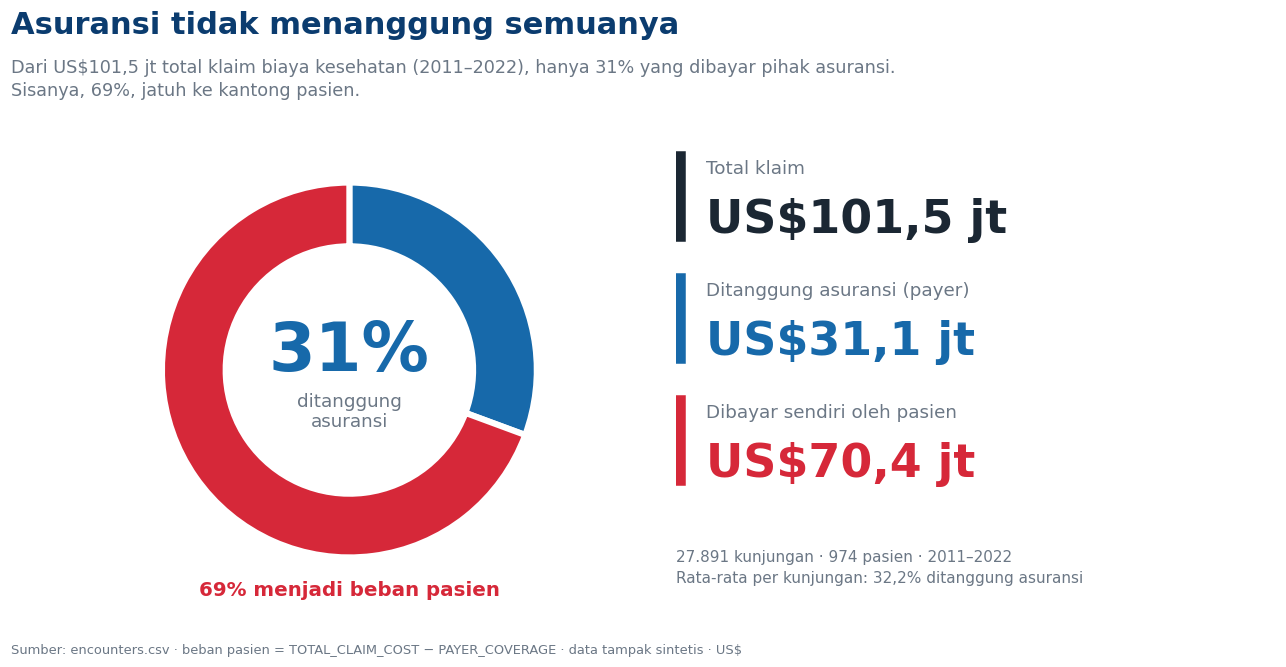

In [4]:
total, covered = enc.TOTAL_CLAIM_COST.sum(), enc.PAYER_COVERAGE.sum()
oop = total - covered
cov_ratio = covered / total
mean_ratio_per_visit = (enc.PAYER_COVERAGE / enc.TOTAL_CLAIM_COST.where(enc.TOTAL_CLAIM_COST > 0)).mean()
n_visits, n_patients = len(enc), enc.PATIENT.nunique()
years = f"{enc.START.min().year}–{enc.START.max().year}"

print(f"Total klaim        : {usd(total, 2)}")
print(f"Ditanggung asuransi: {usd(covered, 2)} ({pct(cov_ratio)})")
print(f"Dibayar pasien     : {usd(oop, 2)} ({pct(1 - cov_ratio)})")
print(f"Rata-rata rasio per kunjungan: {pct(mean_ratio_per_visit)}  (pembanding: rasio agregat {pct(cov_ratio)})")

fig = plt.figure(figsize=(12, 6.2))
top = add_header(fig, "Asuransi tidak menanggung semuanya",
                 f"Dari {usd(total)} total klaim biaya kesehatan ({years}), hanya {pct(cov_ratio, 0)} yang dibayar pihak asuransi.\n"
                 f"Sisanya, {pct(1 - cov_ratio, 0)}, jatuh ke kantong pasien.",
                 source="Sumber: encounters.csv · beban pasien = TOTAL_CLAIM_COST − PAYER_COVERAGE · data tampak sintetis · US$")
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1], left=0.03, right=0.97, top=top, bottom=0.1, wspace=0.02)

ax = fig.add_subplot(gs[0])
ax.pie([covered, oop], colors=[BLUE, RED], startangle=90, counterclock=False,
       wedgeprops=dict(width=0.34, edgecolor="white", linewidth=4))
ax.text(0, 0.10, pct(cov_ratio, 0), ha="center", va="center", fontsize=44, fontweight="bold", color=BLUE)
ax.text(0, -0.22, "ditanggung\nasuransi", ha="center", va="center", fontsize=12, color=GRAY, linespacing=1.2)
ax.text(0, -1.17, f"{pct(1 - cov_ratio, 0)} menjadi beban pasien", ha="center", va="center", fontsize=13, fontweight="bold", color=RED)
ax.set_aspect("equal")

ax2 = fig.add_subplot(gs[1])
ax2.axis("off")
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
items = [(0.86, "Total klaim", usd(total), INK), (0.60, "Ditanggung asuransi (payer)", usd(covered), BLUE),
         (0.34, "Dibayar sendiri oleh pasien", usd(oop), RED)]
for y, label, value, color in items:
    ax2.add_patch(Rectangle((0.0, y - 0.085), 0.014, 0.19, color=color, transform=ax2.transAxes))
    ax2.text(0.05, y + 0.07, label, fontsize=12, color=GRAY, va="center")
    ax2.text(0.05, y - 0.04, value, fontsize=30, fontweight="bold", color=color, va="center")
ax2.text(0.0, 0.08, f"{id_num(n_visits)} kunjungan · {id_num(n_patients)} pasien · {years}\n"
                    f"Rata-rata per kunjungan: {pct(mean_ratio_per_visit)} ditanggung asuransi",
         fontsize=10, color=GRAY, va="center", linespacing=1.5)
save_fig(fig, "01a_hook_donat")
plt.show()

### 1b. Bongkar angka 69%: dari mana beban pasien berasal?
Kalau rata-rata disesuaikan per kelompok penyedia, ceritanya berubah: **bukan "semua asuransi pelit"**, melainkan
jurang antara yang punya perlindungan dan yang tidak.

,visits,total,covered,oop,oop_share,coverage_ratio,n_payers
PAYER_GROUP,,,,,,,
Asuransi aktif,14651,"US$38,2 jt","US$31,1 jt","US$7,1 jt","10,0%","81,5%",4
Asuransi cakupan ≈ 0%,4433,"US$14,1 jt","US$8,6 rb","US$14,1 jt","20,0%","0,1%",5
Tanpa asuransi,8807,"US$49,3 jt",US$0,"US$49,3 jt","70,0%","0,0%",1


-> 90% beban pasien berasal dari kunjungan tanpa asuransi atau dari asuransi ber-coverage ≈ 0%.
-> Pada asuransi yang benar-benar aktif, rasio coverage mencapai 81%.
[tersimpan] output_infografis/01b_bongkar_beban.png


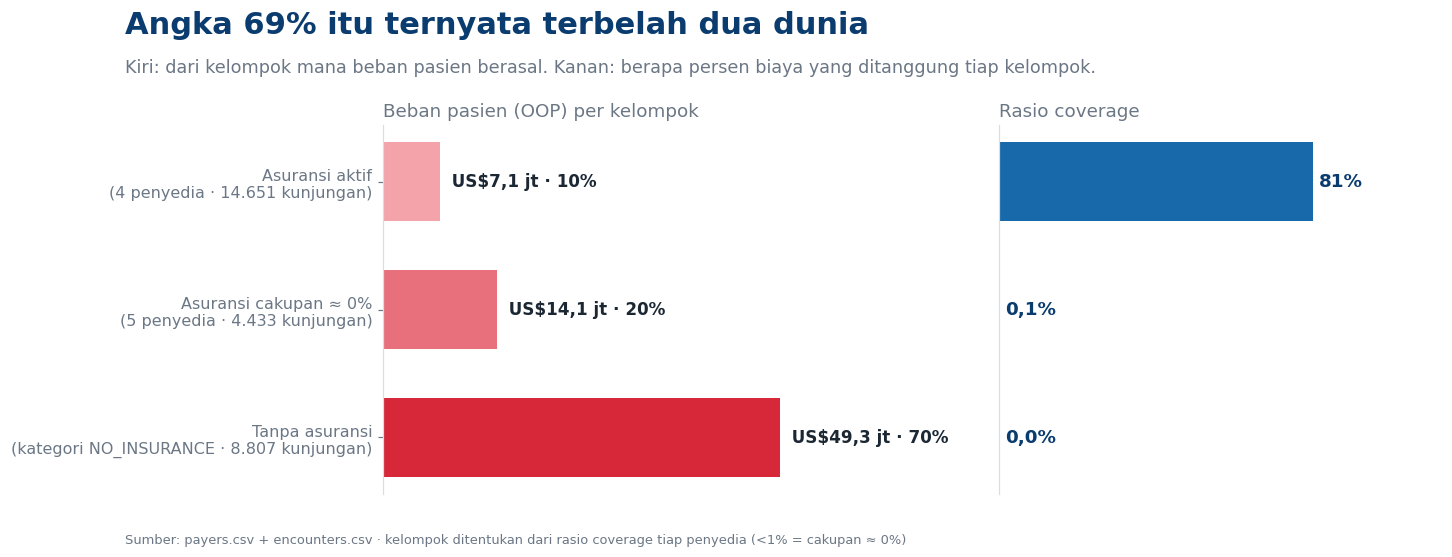

In [5]:
group_stats = enc.groupby("PAYER_GROUP").agg(
    visits=("Id", "count"), total=("TOTAL_CLAIM_COST", "sum"), covered=("PAYER_COVERAGE", "sum"), oop=("OOP", "sum"))
group_stats["oop_share"] = group_stats.oop / group_stats.oop.sum()
group_stats["coverage_ratio"] = group_stats.covered / group_stats.total
group_stats["n_payers"] = payer_stats.groupby("group").size()
group_stats = group_stats.loc[GROUP_ORDER]
display(group_stats.assign(total=lambda d: d.total.map(usd), covered=lambda d: d.covered.map(usd), oop=lambda d: d.oop.map(usd),
                           oop_share=lambda d: d.oop_share.map(pct), coverage_ratio=lambda d: d.coverage_ratio.map(pct)))

g_act, g_zero, g_none = (group_stats.loc[k] for k in GROUP_ORDER)
print(f"-> {pct(g_none.oop_share + g_zero.oop_share, 0)} beban pasien berasal dari kunjungan tanpa asuransi atau dari asuransi ber-coverage ≈ 0%.")
print(f"-> Pada asuransi yang benar-benar aktif, rasio coverage mencapai {pct(g_act.coverage_ratio, 0)}.")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.08}, sharey=True)
top = add_header(fig, "Angka 69% itu ternyata terbelah dua dunia",
                 "Kiri: dari kelompok mana beban pasien berasal. Kanan: berapa persen biaya yang ditanggung tiap kelompok.",
                 source="Sumber: payers.csv + encounters.csv · kelompok ditentukan dari rasio coverage tiap penyedia (<1% = cakupan ≈ 0%)")
fig.subplots_adjust(top=top - 0.02, bottom=0.12, left=0.2, right=0.97)
def group_label(g):
    who = "kategori NO_INSURANCE" if g == "Tanpa asuransi" else f"{int(group_stats.loc[g, 'n_payers'])} penyedia"
    return f"{g}\n({who} · {id_num(group_stats.loc[g, 'visits'])} kunjungan)"


ylabels = [group_label(g) for g in GROUP_ORDER]
ypos = np.arange(len(GROUP_ORDER))[::-1]
bar_cols = [RED_LIGHT, RED_MID, RED]
a1.barh(ypos, group_stats.oop, color=bar_cols, height=0.62)
for y, v, s in zip(ypos, group_stats.oop, group_stats.oop_share):
    a1.text(v, y, f"  {usd(v)} · {pct(s, 0)}", va="center", fontsize=11, fontweight="bold", color=INK)
a1.set_xlim(0, group_stats.oop.max() * 1.45)
a1.set_yticks(ypos, ylabels, fontsize=10.5)
a1.set_title("Beban pasien (OOP) per kelompok", loc="left", fontsize=12, color=GRAY)
a1.xaxis.set_visible(False)
a1.spines["bottom"].set_visible(False)
a2.barh(ypos, group_stats.coverage_ratio * 100, color=BLUE, height=0.62)
for y, v in zip(ypos, group_stats.coverage_ratio):
    a2.text(v * 100 + 1.5, y, pct(v, 1 if v < 0.1 else 0), va="center", fontsize=12, fontweight="bold", color=BLUE_DARK)
a2.set_xlim(0, 115)
a2.set_title("Rasio coverage", loc="left", fontsize=12, color=GRAY)
a2.xaxis.set_visible(False)
a2.spines["bottom"].set_visible(False)
a2.tick_params(left=False)
save_fig(fig, "01b_bongkar_beban")
plt.show()

# BAGIAN 2 · Siapa pasiennya? (The Protagonist)
**Data:** `patients.csv` (`GENDER`, `RACE`, `MARITAL`) + riwayat kunjungan &nbsp;|&nbsp; **Visual:** isotype (1 ikon orang = 1%).

Dua ukuran yang sengaja dibedakan: **volume** (siapa paling sering datang) dan **beban** (siapa paling terbebani per orang).
Karena beban sangat timpang antar-individu, perbandingan kelompok memakai **median**, bukan rata-rata.

In [6]:
GENDER_ID = {"F": "Perempuan", "M": "Laki-laki"}
MARITAL_ID = {"M": "Menikah", "S": "Lajang"}

# --- Tabel level pasien ---
pt = enc.groupby("PATIENT").agg(visits=("Id", "count"), total=("TOTAL_CLAIM_COST", "sum"), oop=("OOP", "sum"))
pt = pt.join(demo.set_index("PATIENT"))
pt["END"] = pt.DEATHDATE.fillna(enc.START.max())                 # usia terakhir tercatat (atau saat wafat)
pt["AGE_END"] = (pt.END - pt.BIRTHDATE).dt.days / 365.25
pt["AGE_GROUP"] = pd.cut(pt.AGE_END, AGE_BINS, labels=AGE_LABELS, right=False)
pt["GENDER_L"] = pt.GENDER.map(GENDER_ID).fillna("Tidak tercatat")
pt["MARITAL_L"] = pt.MARITAL.map(MARITAL_ID).fillna("Tidak tercatat")
pt["RACE_L"] = pt.RACE.str.capitalize()

# --- Volume kunjungan menurut usia SAAT kunjungan ---
age_tbl = enc.groupby("AGE_GROUP", observed=True).agg(
    visits=("Id", "count"), patients=("PATIENT", "nunique"), total=("TOTAL_CLAIM_COST", "sum"),
    covered=("PAYER_COVERAGE", "sum"), oop=("OOP", "sum"))
age_tbl["visit_share"] = age_tbl.visits / age_tbl.visits.sum()
age_tbl["visits_per_patient"] = age_tbl.visits / age_tbl.patients
age_tbl["coverage_ratio"] = age_tbl.covered / age_tbl.total
display(age_tbl.assign(total=lambda d: d.total.map(usd), covered=lambda d: d.covered.map(usd), oop=lambda d: d.oop.map(usd),
                       visit_share=lambda d: d.visit_share.map(pct), visits_per_patient=lambda d: d.visits_per_patient.map(lambda v: id_num(v, 1)),
                       coverage_ratio=lambda d: d.coverage_ratio.map(pct)))
top_age = age_tbl.visit_share.idxmax()
print(f"-> Kelompok usia {top_age} menyumbang {pct(age_tbl.visit_share.max(), 0)} dari seluruh kunjungan "
      f"({age_tbl.loc[top_age, 'visits_per_patient']:.0f} kunjungan per pasien).")

,visits,patients,total,covered,oop,visit_share,visits_per_patient,coverage_ratio
AGE_GROUP,,,,,,,,
<35,2328,140,"US$16,3 jt","US$4,8 jt","US$11,5 jt","8,3%","16,6","29,7%"
35–49,3170,249,"US$12,9 jt","US$4,2 jt","US$8,7 jt","11,4%","12,7","32,7%"
50–64,3527,267,"US$9,3 jt","US$1,3 jt","US$8,0 jt","12,6%","13,2","14,3%"
65+,18866,554,"US$63,0 jt","US$20,7 jt","US$42,3 jt","67,6%","34,1","32,9%"


-> Kelompok usia 65+ menyumbang 68% dari seluruh kunjungan (34 kunjungan per pasien).


### 2a. Isotype: "Bayangkan 100 kunjungan / 100 pasien"

[tersimpan] output_infografis/02a_isotype_pasien.png


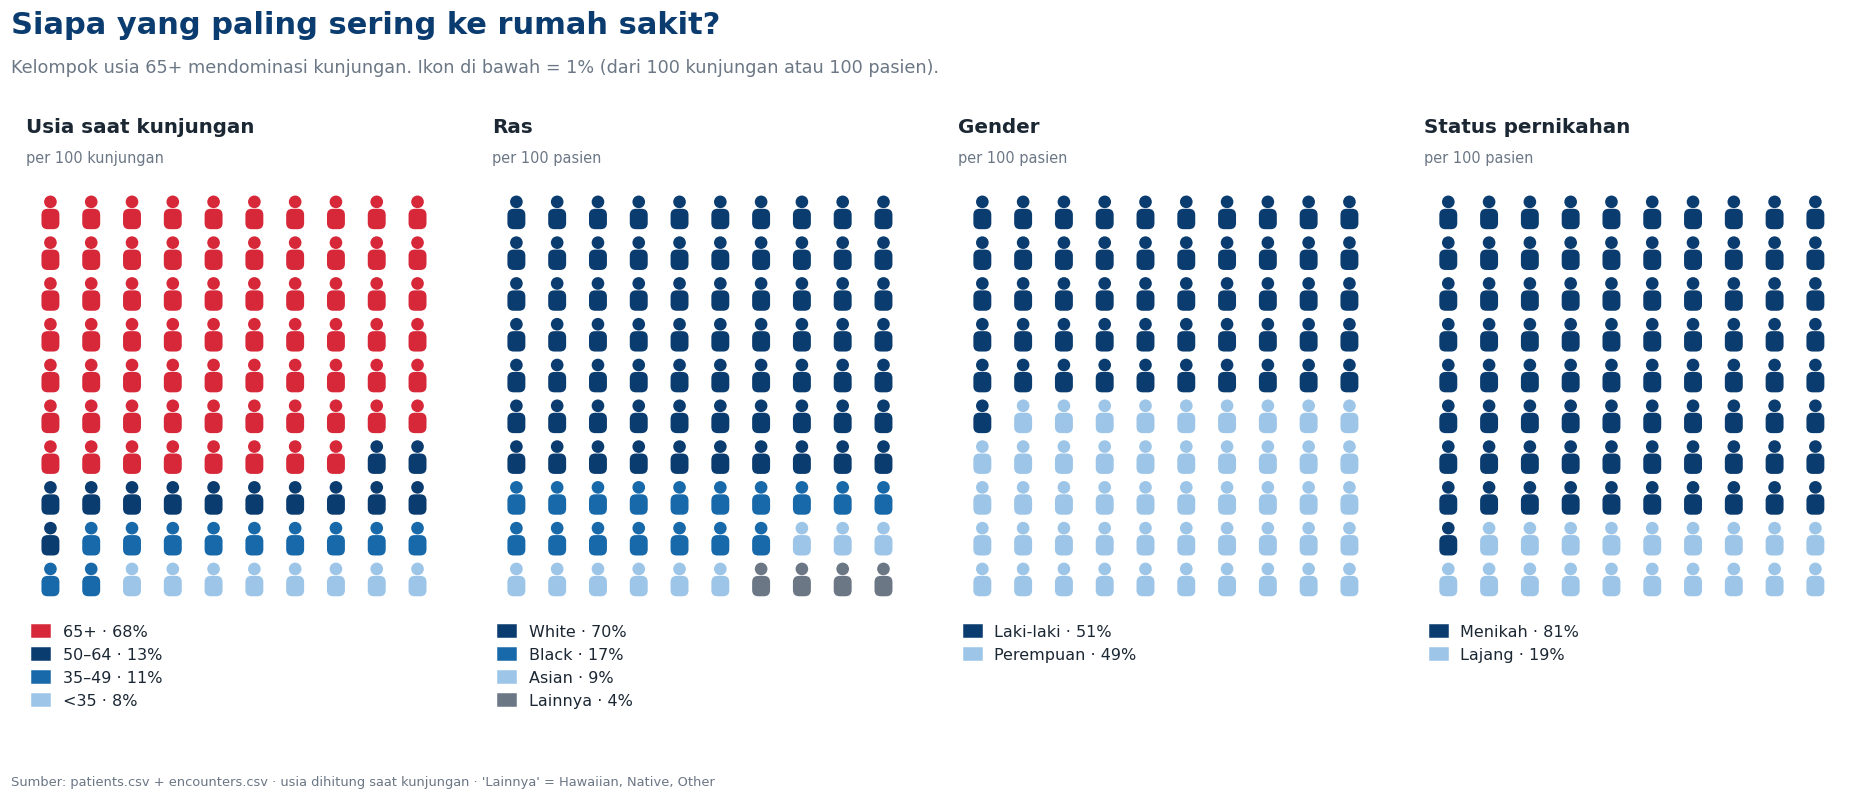

In [7]:
def largest_remainder(shares, total=100):
    """Bagi 100 ikon sesuai proporsi (metode sisa terbesar) agar jumlah selalu tepat 100."""
    s = np.array(shares, float)
    s = s / s.sum() * total
    base = np.floor(s).astype(int)
    for i in np.argsort(-(s - base))[: total - base.sum()]:
        base[i] += 1
    return base


def draw_person(ax, x, y, color):
    ax.add_patch(Circle((x, y + 0.31), 0.155, facecolor=color, edgecolor="none"))
    ax.add_patch(FancyBboxPatch((x - 0.22, y - 0.36), 0.44, 0.5, boxstyle="round,pad=0,rounding_size=0.15",
                                facecolor=color, edgecolor="none"))


def people_waffle(ax, labels, shares, colors, title, subtitle):
    order = np.argsort(-np.array(shares))
    labels, shares, colors = [labels[i] for i in order], [shares[i] for i in order], [colors[i] for i in order]
    counts = largest_remainder(shares)
    cat_of_icon = [i for i, c in enumerate(counts) for _ in range(c)]
    for k, cat in enumerate(cat_of_icon):
        r, c = divmod(k, 10)
        draw_person(ax, c, 9 - r, colors[cat])
    ax.set_xlim(-0.6, 9.6)
    ax.set_ylim(-0.6, 9.6)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.text(0, 1.13, title, transform=ax.transAxes, fontsize=13, fontweight="bold", color=INK, va="bottom")
    ax.text(0, 1.06, subtitle, transform=ax.transAxes, fontsize=9.5, color=GRAY, va="bottom")
    ax.legend(handles=[Patch(color=colors[i], label=f"{labels[i]} · {pct(shares[i], 0)}") for i in range(len(labels))],
              loc="upper left", bbox_to_anchor=(-0.02, -0.01), frameon=False, fontsize=10.5, labelspacing=0.5, handlelength=1.1)


race_share = pt.RACE_L.value_counts(normalize=True)
main_races = race_share.head(3)
race_labels = list(main_races.index) + ["Lainnya"]
race_vals = list(main_races.values) + [race_share.iloc[3:].sum()]
gender_share = pt.GENDER_L.value_counts(normalize=True)
marital_share = pt.MARITAL_L.value_counts(normalize=True)
marital_share = marital_share[marital_share.index != "Tidak tercatat"]
marital_share = marital_share / marital_share.sum()
age_cols = {"65+": RED, "50–64": BLUE_DARK, "35–49": BLUE, "<35": BLUE_LIGHT}

fig = plt.figure(figsize=(17, 7.4))
top = add_header(fig, "Siapa yang paling sering ke rumah sakit?",
                 f"Kelompok usia {top_age} mendominasi kunjungan. Ikon di bawah = 1% (dari 100 kunjungan atau 100 pasien).",
                 source="Sumber: patients.csv + encounters.csv · usia dihitung saat kunjungan · 'Lainnya' = Hawaiian, Native, Other")
axs = fig.subplots(1, 4, gridspec_kw={"left": 0.02, "right": 0.99, "top": top - 0.05, "bottom": 0.2, "wspace": 0.12})
people_waffle(axs[0], list(age_tbl.index), list(age_tbl.visit_share), [age_cols[a] for a in age_tbl.index],
              "Usia saat kunjungan", "per 100 kunjungan")
people_waffle(axs[1], list(race_labels), list(race_vals), [BLUE_DARK, BLUE, BLUE_LIGHT, GRAY], "Ras", "per 100 pasien")
people_waffle(axs[2], list(gender_share.index), list(gender_share.values), [BLUE_DARK, BLUE_LIGHT], "Gender", "per 100 pasien")
people_waffle(axs[3], list(marital_share.index), list(marital_share.values), [BLUE_DARK, BLUE_LIGHT], "Status pernikahan", "per 100 pasien")
save_fig(fig, "02a_isotype_pasien")
plt.show()

### 2b. Siapa yang paling terbebani? (per orang, bukan per total)
Batang = median per pasien. **Merah** = median beban ≥ 1,5× median seluruh pasien dan n ≥ 30 (aturan sederhana agar tidak
menyorot kelompok kecil yang angkanya berisik). Tanda `*` = n < 30, jangan ditafsirkan.

,dimension,group,n,med_visits,med_oop,mean_oop,sum_oop
0,Gender,Laki-laki,494,12.0,"US$6,5 rb","US$77,6 rb","US$38,3 jt"
1,Gender,Perempuan,480,17.0,"US$12,7 rb","US$66,9 rb","US$32,1 jt"
2,Ras,Asian,91,12.0,"US$8,4 rb","US$46,4 rb","US$4,2 jt"
3,Ras,Black,163,15.0,"US$6,6 rb","US$109,6 rb","US$17,9 jt"
4,Ras,Hawaiian,13,20.0,"US$16,2 rb","US$102,3 rb","US$1,3 jt"
5,Ras,Native,11,22.0,"US$8,4 rb","US$518,8 rb","US$5,7 jt"
6,Ras,Other,16,9.5,"US$9,6 rb","US$29,0 rb","US$463,3 rb"
7,Ras,White,680,14.0,"US$9,1 rb","US$60,1 rb","US$40,8 jt"
8,Status nikah,Lajang,189,14.0,"US$8,6 rb","US$33,0 rb","US$6,2 jt"
9,Status nikah,Menikah,784,14.0,"US$8,8 rb","US$81,9 rb","US$64,2 jt"


[tersimpan] output_infografis/02b_beban_per_demografi.png
Kelompok dengan median beban ≥ 1,5× median seluruh pasien (n ≥ 30): <35 (US$13,4 rb), 50–64 (US$20,7 rb)


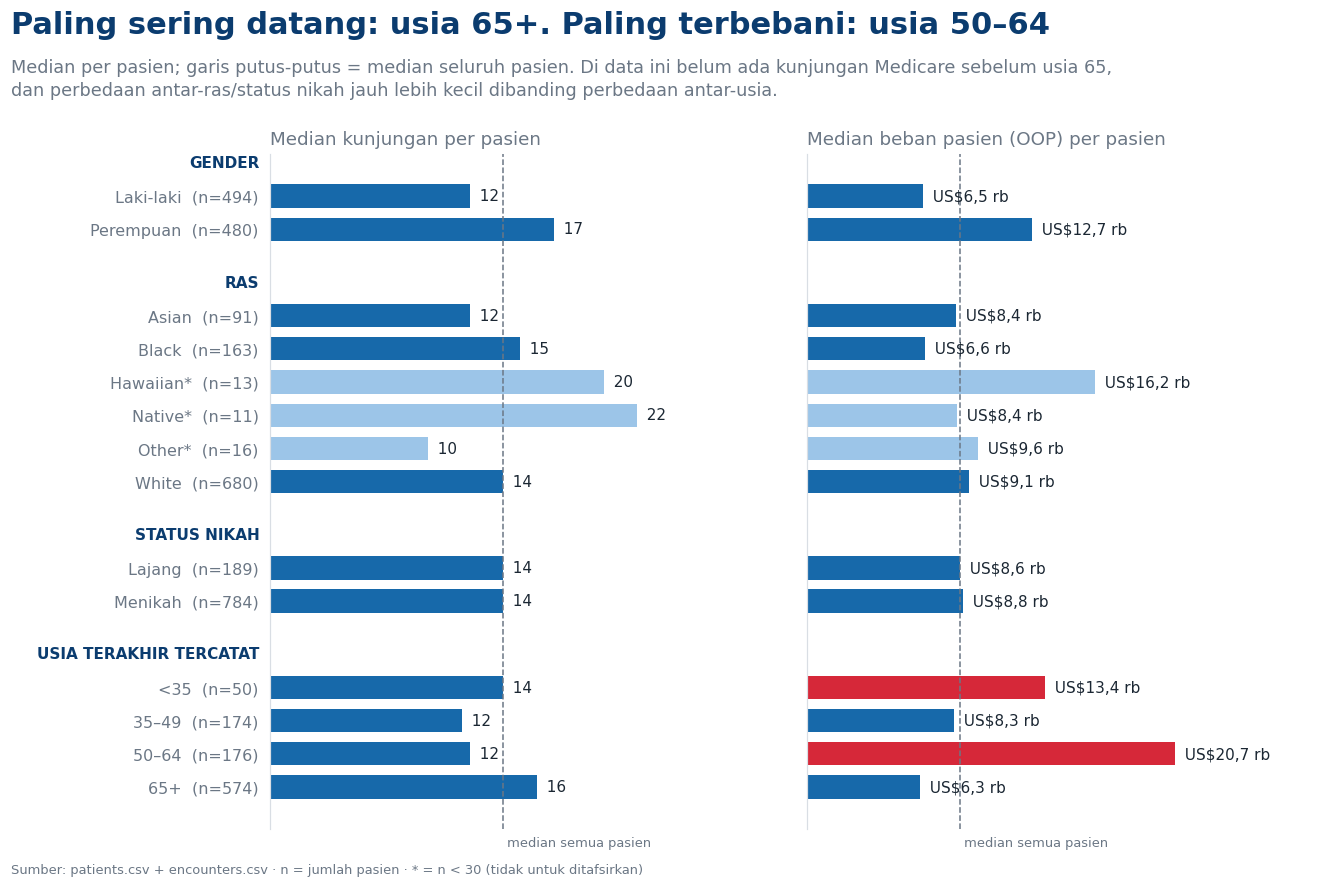

In [8]:
dims = [("Gender", "GENDER_L"), ("Ras", "RACE_L"), ("Status nikah", "MARITAL_L"), ("Usia terakhir tercatat", "AGE_GROUP")]
rows = []
for dim_name, col in dims:
    g = pt.groupby(col, observed=True).agg(n=("visits", "size"), med_visits=("visits", "median"), med_oop=("oop", "median"),
                                           mean_oop=("oop", "mean"), sum_oop=("oop", "sum")).reset_index().rename(columns={col: "group"})
    g.insert(0, "dimension", dim_name)
    rows.append(g)
demo_burden = pd.concat(rows, ignore_index=True)
demo_burden = demo_burden[demo_burden.group != "Tidak tercatat"]
overall_med_oop, overall_med_visits = pt.oop.median(), pt.visits.median()
demo_burden["flag"] = (demo_burden.med_oop >= 1.5 * overall_med_oop) & (demo_burden.n >= 30)
display(demo_burden.assign(group=demo_burden.group.astype(str), med_oop=lambda d: d.med_oop.map(usd), mean_oop=lambda d: d.mean_oop.map(usd),
                           sum_oop=lambda d: d.sum_oop.map(usd)).drop(columns="flag"))

# Susun posisi baris (dengan jeda antar dimensi)
ypos, ylabels, ycolor, y = [], [], [], 0
header_pos = {}
for dim_name, _ in dims:
    sub = demo_burden[demo_burden.dimension == dim_name]
    header_pos[dim_name] = y
    y -= 1
    for _, r in sub.iterrows():
        ypos.append(y)
        ylabels.append(f"{r.group}{'*' if r.n < 30 else ''}  (n={int(r.n)})")
        y -= 1
    y -= 0.6
demo_burden["y"] = ypos

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 8.2), sharey=True, gridspec_kw={"wspace": 0.06})
top = add_header(fig, "Paling sering datang: usia 65+. Paling terbebani: usia 50–64",
                 "Median per pasien; garis putus-putus = median seluruh pasien. Di data ini belum ada kunjungan Medicare sebelum usia 65,\n"
                 "dan perbedaan antar-ras/status nikah jauh lebih kecil dibanding perbedaan antar-usia.",
                 source="Sumber: patients.csv + encounters.csv · n = jumlah pasien · * = n < 30 (tidak untuk ditafsirkan)")
fig.subplots_adjust(top=top - 0.02, bottom=0.07, left=0.2, right=0.96)
for ax_, col, color_flag, ttl, fmt in [(a1, "med_visits", BLUE, "Median kunjungan per pasien", lambda v: id_num(v, 0)),
                                      (a2, "med_oop", RED, "Median beban pasien (OOP) per pasien", usd)]:
    cols = [(color_flag if (f and col == "med_oop") else (BLUE_LIGHT if n < 30 else BLUE)) for f, n in zip(demo_burden.flag, demo_burden.n)]
    ax_.barh(demo_burden.y, demo_burden[col], color=cols, height=0.7)
    for yy, v in zip(demo_burden.y, demo_burden[col]):
        ax_.text(v, yy, f"  {fmt(v)}", va="center", fontsize=10, color=INK)
    ref = overall_med_visits if col == "med_visits" else overall_med_oop
    ax_.axvline(ref, color=GRAY, ls="--", lw=1)
    ax_.text(ref, -0.01, " median semua pasien", transform=ax_.get_xaxis_transform(), fontsize=8.5, color=GRAY, va="top")
    ax_.set_title(ttl, loc="left", fontsize=12, color=GRAY)
    ax_.set_xlim(0, demo_burden[col].max() * 1.38)
    ax_.xaxis.set_visible(False)
    ax_.spines["bottom"].set_visible(False)
    ax_.tick_params(left=False)
for dim_name, yy in header_pos.items():
    a1.text(-0.02, yy, dim_name.upper(), transform=a1.get_yaxis_transform(), ha="right", va="center", fontsize=10, fontweight="bold", color=BLUE_DARK)
a1.set_yticks(demo_burden.y, ylabels, fontsize=10.5)
save_fig(fig, "02b_beban_per_demografi")
plt.show()

flagged = demo_burden[demo_burden.flag]
print("Kelompok dengan median beban ≥ 1,5× median seluruh pasien (n ≥ 30):",
      ", ".join(f"{r.group} ({usd(r.med_oop)})" for r in flagged.itertuples()) or "tidak ada")

# BAGIAN 3 · Ke mana mereka pergi & apa yang terjadi? (The Event)
**Data:** `organizations.csv` (`NAME`, `CITY`) + `encounters.csv` (`ENCOUNTERCLASS`) &nbsp;|&nbsp; **Visual:** bar chart horizontal + peta sederhana.

**Penyesuaian karena data:** `organizations.csv` hanya berisi **satu** rumah sakit, sehingga "membandingkan beberapa institusi tersibuk" tidak
bisa dilakukan. Sebagai gantinya: (a) perbandingan **jenis kunjungan** (volume vs biaya) di RS tersebut, dan (b) **peta asal pasien**
yang datang ke RS itu. Kode ranking antar-RS tetap disiapkan dan otomatis aktif bila data memuat lebih dari satu organisasi.

In [9]:
CLASS_LABEL = {"ambulatory": "Ambulatory", "outpatient": "Outpatient", "urgentcare": "Urgent care",
               "emergency": "Emergency (UGD)", "inpatient": "Inpatient (rawat inap)", "wellness": "Wellness (cek rutin)"}

class_stats = enc.groupby("ENCOUNTERCLASS").agg(
    visits=("Id", "count"), total=("TOTAL_CLAIM_COST", "sum"), covered=("PAYER_COVERAGE", "sum"), oop=("OOP", "sum"),
    mean_claim=("TOTAL_CLAIM_COST", "mean"), median_claim=("TOTAL_CLAIM_COST", "median"))
class_stats["visit_share"] = class_stats.visits / class_stats.visits.sum()
class_stats["cost_share"] = class_stats.total / class_stats.total.sum()
class_stats["coverage_ratio"] = class_stats.covered / class_stats.total
class_stats["label"] = class_stats.index.map(lambda c: CLASS_LABEL.get(c, c))
class_stats = class_stats.sort_values("visits", ascending=False)
display(class_stats.drop(columns="label").assign(
    total=lambda d: d.total.map(usd), covered=lambda d: d.covered.map(usd), oop=lambda d: d.oop.map(usd),
    mean_claim=lambda d: d.mean_claim.map(usd), median_claim=lambda d: d.median_claim.map(usd),
    visit_share=lambda d: d.visit_share.map(pct), cost_share=lambda d: d.cost_share.map(pct), coverage_ratio=lambda d: d.coverage_ratio.map(pct)))

org_stats = (enc.groupby(["ORGANIZATION", "ORG_NAME", "ORG_CITY"], dropna=False)
             .agg(visits=("Id", "count"), patients=("PATIENT", "nunique"), total=("TOTAL_CLAIM_COST", "sum"), covered=("PAYER_COVERAGE", "sum"))
             .reset_index().sort_values("visits", ascending=False))
org_stats["coverage_ratio"] = org_stats.covered / org_stats.total
if len(org_stats) == 1:
    o = org_stats.iloc[0]
    print(f"Seluruh {id_num(o.visits)} kunjungan ({usd(o.total)} klaim) terjadi di satu fasilitas: {str(o.ORG_NAME).title()}, {str(o.ORG_CITY).title()}.")
else:
    display(org_stats)

,visits,total,covered,oop,mean_claim,median_claim,visit_share,cost_share,coverage_ratio
ENCOUNTERCLASS,,,,,,,,,
ambulatory,12537,"US$36,3 jt","US$12,9 jt","US$23,4 jt","US$2,9 rb",US$574,"44,9%","35,7%","35,6%"
outpatient,6300,"US$14,1 jt","US$3,8 jt","US$10,3 jt","US$2,2 rb",US$279,"22,6%","13,9%","26,8%"
urgentcare,3666,"US$23,3 jt","US$3,1 jt","US$20,3 jt","US$6,4 rb",US$143,"13,1%","23,0%","13,1%"
emergency,2322,"US$10,8 jt","US$3,2 jt","US$7,5 jt","US$4,6 rb",US$146,"8,3%","10,6%","30,2%"
wellness,1931,"US$8,2 jt","US$4,4 jt","US$3,8 jt","US$4,3 rb","US$1,2 rb","6,9%","8,1%","53,7%"
inpatient,1135,"US$8,8 jt","US$3,7 jt","US$5,1 jt","US$7,8 rb","US$2,4 rb","4,1%","8,7%","41,9%"


Seluruh 27.891 kunjungan (US$101,5 jt klaim) terjadi di satu fasilitas: Massachusetts General Hospital, Boston.


### 3a. Volume vs biaya: siapa "pelanggan terbanyak" dan siapa "penyedot dana terbesar"?

[tersimpan] output_infografis/03a_volume_vs_biaya.png


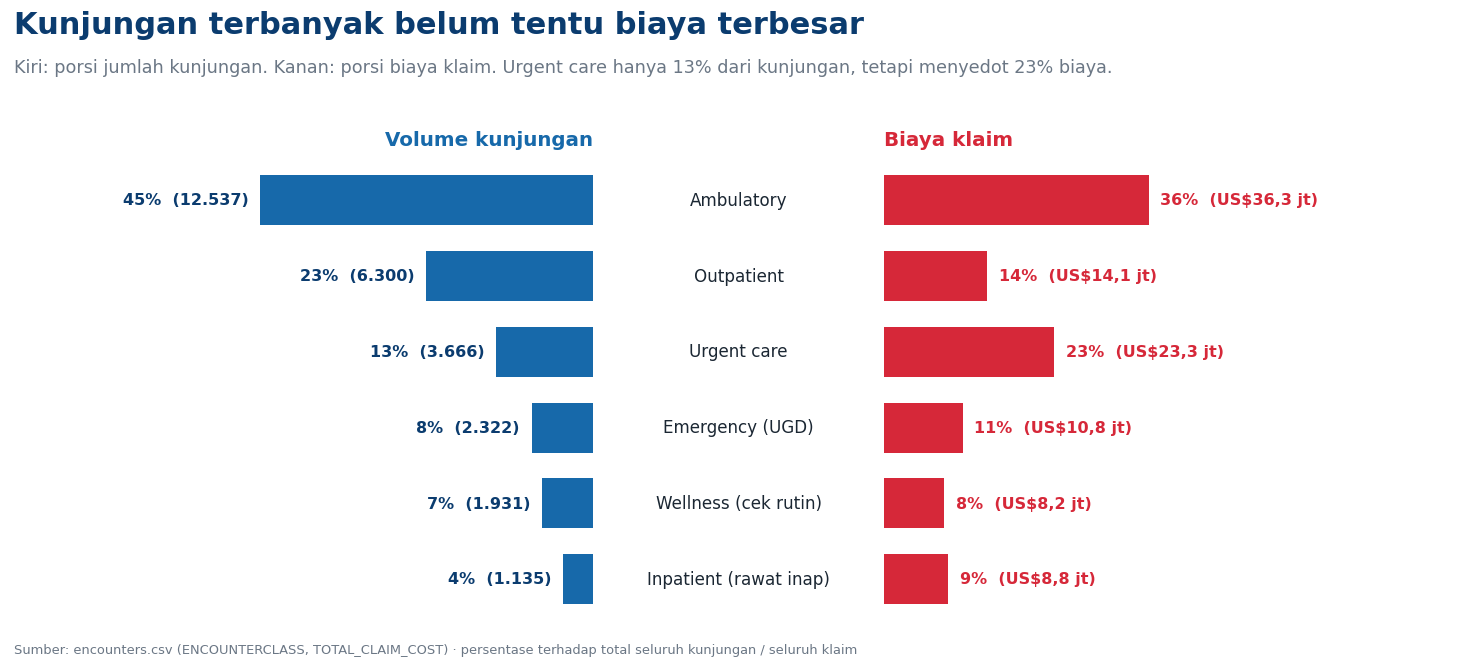

In [10]:
cs = class_stats
y = np.arange(len(cs))[::-1]
lim = max(cs.visit_share.max(), cs.cost_share.max()) * 100 * 1.75

gap_cls = (cs.cost_share - cs.visit_share).idxmax()      # jenis kunjungan dengan selisih porsi biaya − porsi volume terbesar
gap_row = cs.loc[gap_cls]
fig = plt.figure(figsize=(13.5, 6.2))
top = add_header(fig, "Kunjungan terbanyak belum tentu biaya terbesar",
                 f"Kiri: porsi jumlah kunjungan. Kanan: porsi biaya klaim. {gap_row.label} hanya {pct(gap_row.visit_share, 0)} dari kunjungan, "
                 f"tetapi menyedot {pct(gap_row.cost_share, 0)} biaya.",
                 source="Sumber: encounters.csv (ENCOUNTERCLASS, TOTAL_CLAIM_COST) · persentase terhadap total seluruh kunjungan / seluruh klaim")
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.5, 1], left=0.01, right=0.99, top=top - 0.06, bottom=0.07, wspace=0.0)
axL, axM, axR = (fig.add_subplot(gs[i]) for i in range(3))
axL.barh(y, cs.visit_share * 100, color=BLUE, height=0.66)
axR.barh(y, cs.cost_share * 100, color=RED, height=0.66)
for yy, v, n in zip(y, cs.visit_share * 100, cs.visits):
    axL.text(v + lim * 0.02, yy, f"{pct(v / 100, 0)}  ({id_num(n)})", ha="right", va="center", fontsize=10.5, fontweight="bold", color=BLUE_DARK)
for yy, v, t in zip(y, cs.cost_share * 100, cs.total):
    axR.text(v + lim * 0.02, yy, f"{pct(v / 100, 0)}  ({usd(t)})", ha="left", va="center", fontsize=10.5, fontweight="bold", color=RED)
axL.set_xlim(lim, 0)
axR.set_xlim(0, lim)
axM.set_xlim(0, 1)
for ax_ in (axL, axM, axR):
    ax_.set_ylim(-0.6, len(cs) - 0.4)
    ax_.axis("off")
for yy, lab in zip(y, cs.label):
    axM.text(0.5, yy, lab, ha="center", va="center", fontsize=11, color=INK)
axL.set_title("Volume kunjungan", fontsize=13, color=BLUE, fontweight="bold", loc="right")
axR.set_title("Biaya klaim", fontsize=13, color=RED, fontweight="bold", loc="left")
save_fig(fig, "03a_volume_vs_biaya")
plt.show()

### 3b. Rata-rata biaya per kunjungan & siapa yang menanggung
Rata-rata sangat ditarik oleh segelintir klaim ekstrem, jadi **median** ditampilkan sebagai pembanding jujur.

[tersimpan] output_infografis/03b_biaya_per_kunjungan.png


PAYER_GROUP,Asuransi aktif,Asuransi cakupan ≈ 0%,Tanpa asuransi
ENCOUNTERCLASS,,,
Ambulatory,48%,16%,36%
Emergency (UGD),68%,8%,24%
Inpatient (rawat inap),54%,17%,29%
Outpatient,51%,24%,26%
Urgent care,55%,4%,41%
Wellness (cek rutin),62%,20%,17%


-> Urgent care: 13% biaya ditanggung secara keseluruhan, tetapi 78% bila hanya dihitung kunjungan dengan asuransi aktif. Rendahnya coverage lebih dipengaruhi bauran pasien (banyak yang tanpa asuransi) daripada jenis layanannya.


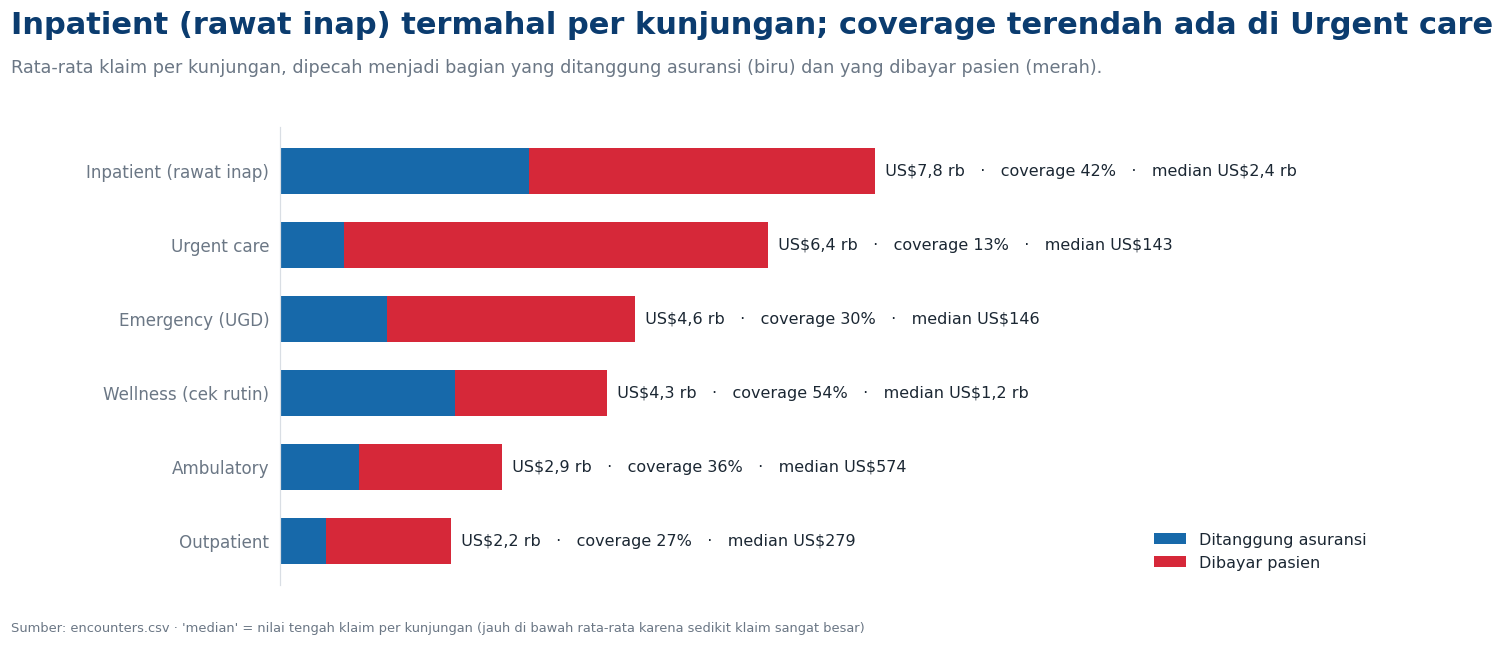

In [11]:
cb = class_stats.sort_values("mean_claim", ascending=False)
y = np.arange(len(cb))[::-1]
fig, ax = plt.subplots(figsize=(13, 6))
priciest, leakiest = cb.iloc[0], cb.sort_values("coverage_ratio").iloc[0]
top = add_header(fig, f"{priciest.label} termahal per kunjungan; coverage terendah ada di {leakiest.label}",
                 "Rata-rata klaim per kunjungan, dipecah menjadi bagian yang ditanggung asuransi (biru) dan yang dibayar pasien (merah).",
                 source="Sumber: encounters.csv · 'median' = nilai tengah klaim per kunjungan (jauh di bawah rata-rata karena sedikit klaim sangat besar)")
fig.subplots_adjust(top=top - 0.02, bottom=0.1, left=0.2, right=0.97)
cov_pv, oop_pv = cb.covered / cb.visits, cb.oop / cb.visits
ax.barh(y, cov_pv, color=BLUE, height=0.62, label="Ditanggung asuransi")
ax.barh(y, oop_pv, left=cov_pv, color=RED, height=0.62, label="Dibayar pasien")
for yy, m, med, r in zip(y, cb.mean_claim, cb.median_claim, cb.coverage_ratio):
    ax.text(m, yy, f"  {usd(m)}   ·   coverage {pct(r, 0)}   ·   median {usd(med)}", va="center", fontsize=10.5, color=INK)
ax.set_yticks(y, cb.label, fontsize=11)
ax.set_xlim(0, cb.mean_claim.max() * 1.85)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.tick_params(left=False)
ax.legend(loc="lower right", frameon=False, fontsize=10.5)
save_fig(fig, "03b_biaya_per_kunjungan")
plt.show()

# Mengapa urgent care coverage-nya rendah? Cek bauran penyedia (bukan semata "jenis layanan")
mix = pd.crosstab(enc.ENCOUNTERCLASS, enc.PAYER_GROUP, normalize="index")[GROUP_ORDER]
mix.index = mix.index.map(lambda c: CLASS_LABEL.get(c, c))
fmt_mix = mix.map(lambda v: pct(v, 0)) if hasattr(mix, "map") else mix.applymap(lambda v: pct(v, 0))
display(fmt_mix)
uc = enc[enc.ENCOUNTERCLASS == "urgentcare"]
uc_active = uc[uc.PAYER_GROUP == "Asuransi aktif"]
uc_all_ratio = uc.PAYER_COVERAGE.sum() / uc.TOTAL_CLAIM_COST.sum()
uc_active_ratio = uc_active.PAYER_COVERAGE.sum() / uc_active.TOTAL_CLAIM_COST.sum()
print(f"-> Urgent care: {pct(uc_all_ratio, 0)} biaya ditanggung secara keseluruhan, tetapi {pct(uc_active_ratio, 0)} bila hanya dihitung "
      f"kunjungan dengan asuransi aktif. Rendahnya coverage lebih dipengaruhi bauran pasien (banyak yang tanpa asuransi) daripada jenis layanannya.")

### 3c. Peta sederhana: dari mana pasien datang ke rumah sakit ini?
Warna titik = total beban pasien (skala log), ukuran = jumlah kunjungan. Tanpa peta dasar (basemap) agar tidak perlu library tambahan;
untuk peta interaktif dengan jalan dan batas kota, koordinat yang sama bisa dimasukkan ke `folium` atau Datawrapper.

Pasien berasal dari 29 kota; Boston = 56% pasien.
[tersimpan] output_infografis/03c_peta_asal_pasien.png


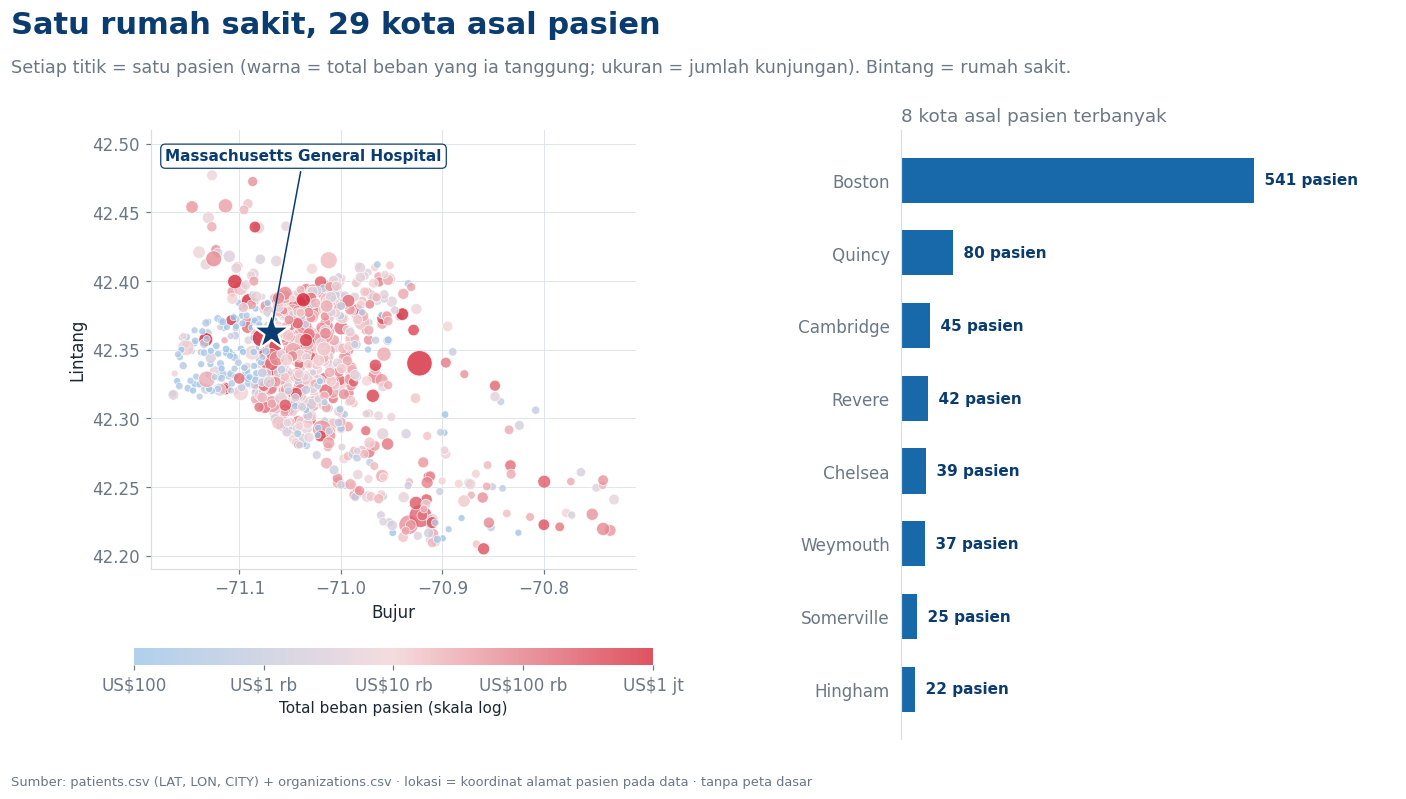

In [12]:
city_tbl = (pt.groupby("PATIENT_CITY").agg(patients=("visits", "size"), visits=("visits", "sum"), oop=("oop", "sum"),
                                           med_oop=("oop", "median"), lat=("LAT", "mean"), lon=("LON", "mean"))
            .sort_values("patients", ascending=False))
print(f"Pasien berasal dari {len(city_tbl)} kota; {city_tbl.index[0]} = {pct(city_tbl.patients.iloc[0] / city_tbl.patients.sum(), 0)} pasien.")

cmap = LinearSegmentedColormap.from_list("oop", [BLUE_LIGHT, "#F3D3D6", RED])
fig = plt.figure(figsize=(13, 7.4))
n_fac = org.shape[0]
fac_txt = "Satu rumah sakit" if n_fac == 1 else f"{n_fac} fasilitas"
top = add_header(fig, f"{fac_txt}, {len(city_tbl)} kota asal pasien",
                 "Setiap titik = satu pasien (warna = total beban yang ia tanggung; ukuran = jumlah kunjungan). Bintang = rumah sakit.",
                 source="Sumber: patients.csv (LAT, LON, CITY) + organizations.csv · lokasi = koordinat alamat pasien pada data · tanpa peta dasar")
gs = fig.add_gridspec(1, 2, width_ratios=[1.5, 1], left=0.02, right=0.98, top=top - 0.02, bottom=0.08, wspace=0.22)
ax = fig.add_subplot(gs[0])
logoop = np.log10(pt.oop.clip(lower=10))
sc = ax.scatter(pt.LON, pt.LAT, c=logoop, s=14 + 7 * np.sqrt(pt.visits), cmap=cmap, vmin=2, vmax=6, alpha=0.8,
                edgecolor="white", linewidth=0.5, zorder=2)
for r in org.itertuples():
    ax.scatter(r.LON, r.LAT, marker="*", s=650, color=BLUE_DARK, edgecolor="white", linewidth=1.5, zorder=5)
    ax.annotate(r.NAME.title(), (r.LON, r.LAT), xytext=(0.03, 0.93), textcoords="axes fraction", ha="left", fontsize=10,
                fontweight="bold", color=BLUE_DARK, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=BLUE_DARK, lw=0.8),
                arrowprops=dict(arrowstyle="-", color=BLUE_DARK, lw=1), zorder=6)
ax.set_aspect(1 / np.cos(np.radians(pt.LAT.mean())))
ax.set_xlabel("Bujur")
ax.set_ylabel("Lintang")
ax.grid(color=GRAY_LIGHT, lw=0.5)
ax.set_axisbelow(True)
cb_ = fig.colorbar(sc, ax=ax, orientation="horizontal", shrink=0.7, pad=0.13, aspect=30)
cb_.set_ticks([2, 3, 4, 5, 6])
cb_.set_ticklabels([usd(10 ** t, 0) for t in [2, 3, 4, 5, 6]])
cb_.set_label("Total beban pasien (skala log)", fontsize=10)
cb_.outline.set_visible(False)

ax2 = fig.add_subplot(gs[1])
tc = city_tbl.head(8).iloc[::-1]
ax2.barh(tc.index, tc.patients, color=BLUE, height=0.62)
for yy, (name, r) in enumerate(tc.iterrows()):
    ax2.text(r.patients, yy, f"  {int(r.patients)} pasien", va="center", fontsize=10, color=BLUE_DARK, fontweight="bold")
ax2.set_xlim(0, tc.patients.max() * 1.4)
ax2.xaxis.set_visible(False)
ax2.spines["bottom"].set_visible(False)
ax2.tick_params(left=False)
ax2.set_title("8 kota asal pasien terbanyak", loc="left", fontsize=12, color=GRAY)
save_fig(fig, "03c_peta_asal_pasien")
plt.show()

In [13]:
# Ranking antar-institusi: hanya aktif jika data memuat lebih dari satu organisasi
def plot_org_ranking(org_stats, top_n=8):
    d = org_stats.head(top_n).iloc[::-1]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True, gridspec_kw={"wspace": 0.05})
    top = add_header(fig, "Institusi tersibuk: volume vs biaya", "Kiri: jumlah kunjungan. Kanan: total klaim.", source="Sumber: organizations.csv + encounters.csv")
    fig.subplots_adjust(top=top - 0.02, left=0.28)
    a1.barh(d.ORG_NAME, d.visits, color=BLUE)
    a2.barh(d.ORG_NAME, d.total, color=RED)
    a2.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: usd(v, 0)))
    save_fig(fig, "03d_ranking_institusi")
    plt.show()


if len(org_stats) > 1:
    plot_org_ranking(org_stats)
else:
    print("organizations.csv hanya memuat 1 fasilitas -> ranking antar-institusi dilewati (kode siap pakai bila data diperluas).")

organizations.csv hanya memuat 1 fasilitas -> ranking antar-institusi dilewati (kode siap pakai bila data diperluas).


# BAGIAN 4 · Prosedur paling menguras kantong (The Action)
**Data:** `procedures.csv` (`DESCRIPTION`, `BASE_COST`, `REASONDESCRIPTION`) &nbsp;|&nbsp; **Visual:** bubble chart + tabel top 5.

Dua cara melihat "mahal": **harga per tindakan** (yang paling mengejutkan) dan **total belanja** (harga × seberapa sering dilakukan).
Keduanya menghasilkan jawaban yang sangat berbeda, dan di situlah ceritanya.

In [14]:
MIN_N = 3  # abaikan tindakan yang hanya tercatat 1–2 kali agar peringkat harga tidak ditentukan satu kasus

GLOSS_PROC = {
    "Admit to ICU": "Rawat di ICU", "Coronary artery bypass grafting": "Bypass jantung (CABG)",
    "Lumpectomy of breast": "Lumpektomi payudara", "Hemodialysis": "Hemodialisis (cuci darah)",
    "Insertion of biventricular implantable cardioverter defibrillator": "ICD biventrikular",
    "Electrical cardioversion": "Kardioversi listrik", "Combined chemotherapy and radiation therapy": "Kemoterapi + radioterapi",
    "Colonoscopy": "Kolonoskopi", "Catheter ablation of tissue of heart": "Ablasi kateter jantung",
    "Renal dialysis": "Dialisis ginjal", "Auscultation of the fetal heart": "Pemeriksaan detak jantung janin",
    "Evaluation of uterine fundal height": "Ukur tinggi fundus rahim",
    "Assessment of health and social care needs": "Asesmen kebutuhan kesehatan & sosial",
}
GLOSS_REASON = {
    "Septic shock": "syok septik", "Myocardial Infarction": "serangan jantung", "Malignant neoplasm of breast": "kanker payudara",
    "Cardiac Arrest": "henti jantung", "Atrial Fibrillation": "fibrilasi atrium", "Normal pregnancy": "kehamilan normal",
    "Stroke": "stroke", "Pulmonary emphysema": "emfisema paru", "Chronic obstructive bronchitis": "bronkitis obstruktif kronik",
}


def clean(s):
    return " ".join(str(s).replace("(procedure)", "").replace("(disorder)", "").replace("(finding)", "").split())


def proc_name(desc):
    c = clean(desc)
    return GLOSS_PROC.get(c, c)


def reason_name(r):
    if pd.isna(r):
        return "Tidak tercatat di data"
    c = clean(r)
    return f"{c} ({GLOSS_REASON[c]})" if c in GLOSS_REASON else c


proc_stats = proc.groupby("DESCRIPTION").agg(n=("BASE_COST", "size"), unit_cost=("BASE_COST", "mean"), min_cost=("BASE_COST", "min"),
                                             max_cost=("BASE_COST", "max"), total=("BASE_COST", "sum"))
main_reason = (proc.dropna(subset=["REASONDESCRIPTION"]).groupby("DESCRIPTION")["REASONDESCRIPTION"].agg(lambda s: s.value_counts().index[0]))
proc_stats["reason"] = main_reason.reindex(proc_stats.index).map(reason_name)
proc_stats["reason"] = proc_stats["reason"].fillna("Tidak tercatat di data")
proc_stats["name"] = [proc_name(d) for d in proc_stats.index]
proc_stats["spend_share"] = proc_stats.total / proc_stats.total.sum()

print(f"{len(proc_stats)} jenis tindakan · {id_num(len(proc))} tindakan tercatat · total BASE_COST {usd(proc.BASE_COST.sum())}")
print(f"Hanya {pct(proc.REASONDESCRIPTION.notna().mean())} baris tindakan yang mencatat alasan medis (REASONDESCRIPTION).")

top5 = proc_stats[proc_stats.n >= MIN_N].nlargest(5, "unit_cost")
display(top5.reset_index(drop=True)[["name", "unit_cost", "n", "total", "reason"]].assign(
    unit_cost=lambda d: d.unit_cost.map(usd), total=lambda d: d.total.map(usd)).rename(
    columns={"name": "tindakan", "unit_cost": "harga rata-rata", "n": "jumlah kasus", "total": "total belanja", "reason": "alasan medis utama"}))

163 jenis tindakan · 47.701 tindakan tercatat · total BASE_COST US$105,5 jt
Hanya 22,5% baris tindakan yang mencatat alasan medis (REASONDESCRIPTION).


,tindakan,harga rata-rata,jumlah kasus,total belanja,alasan medis utama
0,Rawat di ICU,"US$206,3 rb",5,"US$1,0 jt",Septic shock (syok septik)
1,Bypass jantung (CABG),"US$47,1 rb",9,"US$423,8 rb",Myocardial Infarction (serangan jantung)
2,Lumpektomi payudara,"US$29,4 rb",5,"US$146,8 rb",Malignant neoplasm of breast (kanker payudara)
3,Hemodialisis (cuci darah),"US$29,3 rb",27,"US$791,1 rb",Tidak tercatat di data
4,ICD biventrikular,"US$27,2 rb",4,"US$108,8 rb",Cardiac Arrest (henti jantung)


### 4a. Top 5 tindakan dengan harga dasar termahal (gelembung = harga)

[tersimpan] output_infografis/04a_top5_prosedur_termahal.png


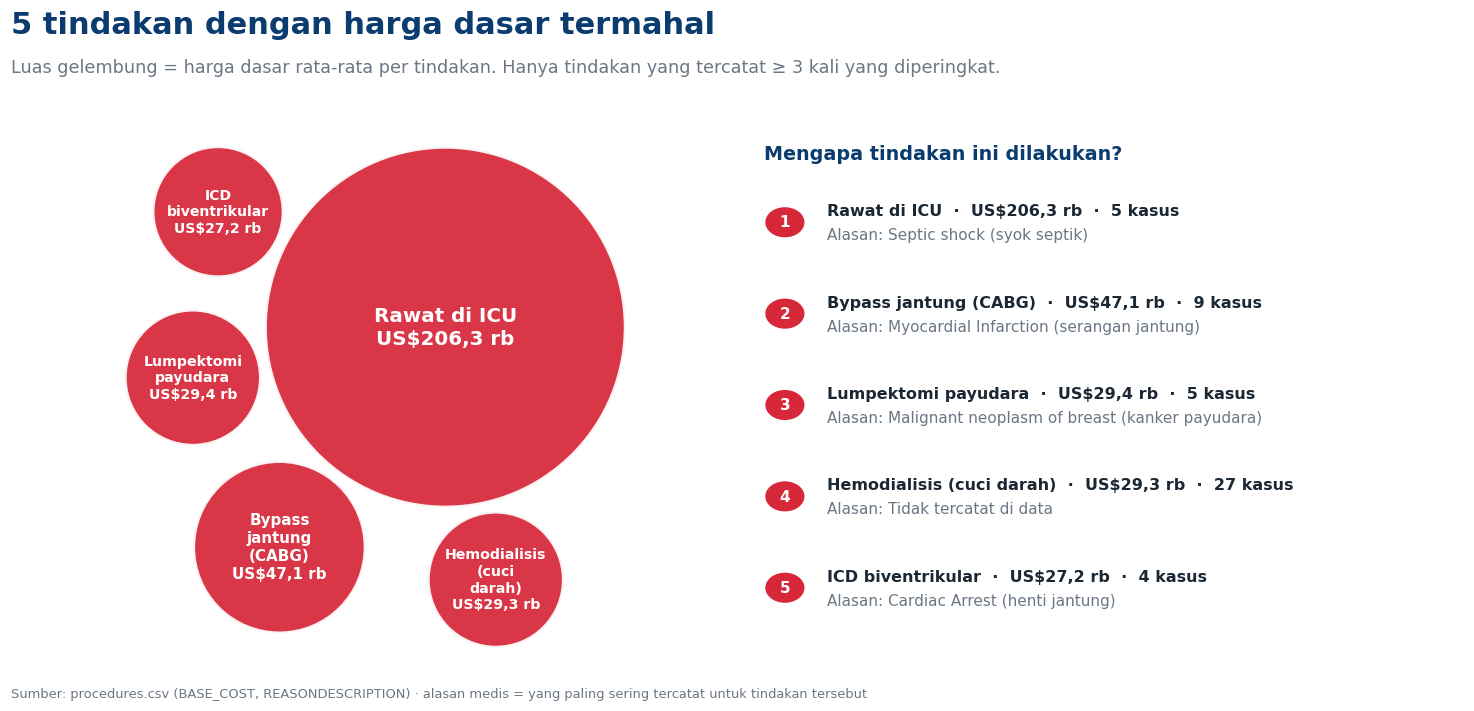

In [15]:
def pack_circles(radii, gap=0.05, step=0.02, extent=4.0):
    """Susun lingkaran tanpa tumpang tindih; yang terbesar di pusat, lainnya sedekat mungkin ke pusat."""
    radii = np.asarray(radii, float)
    order = np.argsort(-radii)
    pos = np.zeros((len(radii), 2))
    placed = []
    g = np.arange(-extent, extent + step, step)
    X, Y = np.meshgrid(g, g)
    for k, i in enumerate(order):
        if k > 0:
            ok = np.ones_like(X, bool)
            for j in placed:
                ok &= np.hypot(X - pos[j, 0], Y - pos[j, 1]) >= radii[i] + radii[j] + gap
            d = np.where(ok, np.hypot(X, Y), np.inf)
            iy, ix = np.unravel_index(np.argmin(d), d.shape)
            pos[i] = (X[iy, ix], Y[iy, ix])
        placed.append(i)
    return pos


t5 = top5.reset_index(drop=True)
radii = np.sqrt(t5.unit_cost / t5.unit_cost.max())          # luas gelembung ∝ harga
pos = pack_circles(radii)

fig = plt.figure(figsize=(13.5, 6.6))
top = add_header(fig, "5 tindakan dengan harga dasar termahal",
                 f"Luas gelembung = harga dasar rata-rata per tindakan. Hanya tindakan yang tercatat ≥ {MIN_N} kali yang diperingkat.",
                 source="Sumber: procedures.csv (BASE_COST, REASONDESCRIPTION) · alasan medis = yang paling sering tercatat untuk tindakan tersebut")
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1], left=0.01, right=0.99, top=top - 0.02, bottom=0.07, wspace=0.03)
ax = fig.add_subplot(gs[0])
for (cx, cy), r, row in zip(pos, radii, t5.itertuples()):
    ax.add_patch(Circle((cx, cy), r, facecolor=RED, edgecolor="white", linewidth=2.5, alpha=0.93))
    wrapped = textwrap.fill(row.name, width=max(11, int(r * 20)), break_long_words=False)
    ax.text(cx, cy, f"{wrapped}\n{usd(row.unit_cost)}", ha="center", va="center",
            color="white", fontweight="bold", fontsize=float(np.clip(7 + 6 * r, 8.5, 13)), linespacing=1.25)
ax.set_xlim((pos[:, 0] - radii).min() - 0.1, (pos[:, 0] + radii).max() + 0.1)
ax.set_ylim((pos[:, 1] - radii).min() - 0.1, (pos[:, 1] + radii).max() + 0.1)
ax.set_aspect("equal")
ax.axis("off")

ax2 = fig.add_subplot(gs[1])
ax2.axis("off")
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.text(0.0, 0.97, "Mengapa tindakan ini dilakukan?", fontsize=12.5, fontweight="bold", color=BLUE_DARK, va="top")
step_y = 0.17
for i, row in enumerate(t5.itertuples()):
    yy = 0.86 - i * step_y
    ax2.add_patch(Circle((0.03, yy - 0.035), 0.028, facecolor=RED, transform=ax2.transAxes))
    ax2.text(0.03, yy - 0.035, str(i + 1), color="white", fontsize=10, fontweight="bold", ha="center", va="center")
    ax2.text(0.09, yy, f"{row.name}  ·  {usd(row.unit_cost)}  ·  {row.n} kasus", fontsize=10.5, fontweight="bold", color=INK, va="top")
    ax2.text(0.09, yy - 0.045, f"Alasan: {textwrap.fill(row.reason, 46)}", fontsize=10, color=GRAY, va="top")
save_fig(fig, "04a_top5_prosedur_termahal")
plt.show()

### 4b. Plot twist: yang termahal per tindakan ≠ yang paling menguras dana
Sumbu X = seberapa sering tindakan dilakukan, sumbu Y = harga per tindakan, ukuran gelembung = **total belanja** (harga × frekuensi).

-> Kardioversi listrik: 1.383 kali × US$25,9 rb = US$35,8 jt (34% dari seluruh belanja tindakan). Alasan utama: Atrial Fibrillation (fibrilasi atrium).
[tersimpan] output_infografis/04b_harga_vs_frekuensi.png


,tindakan,harga rata-rata,jumlah,total belanja,porsi,alasan medis utama
0,Kardioversi listrik,"US$25,9 rb",1383,"US$35,8 jt","34,0%",Atrial Fibrillation (fibrilasi atrium)
1,Pemeriksaan detak jantung janin,"US$5,3 rb",1065,"US$5,7 jt","5,4%",Normal pregnancy (kehamilan normal)
2,Ukur tinggi fundus rahim,"US$5,3 rb",1065,"US$5,6 jt","5,3%",Normal pregnancy (kehamilan normal)
3,Kemoterapi + radioterapi,"US$11,8 rb",444,"US$5,2 jt","5,0%",Non-small cell carcinoma of lung TNM stage 1
4,Kolonoskopi,"US$11,8 rb",424,"US$5,0 jt","4,8%",Tidak tercatat di data


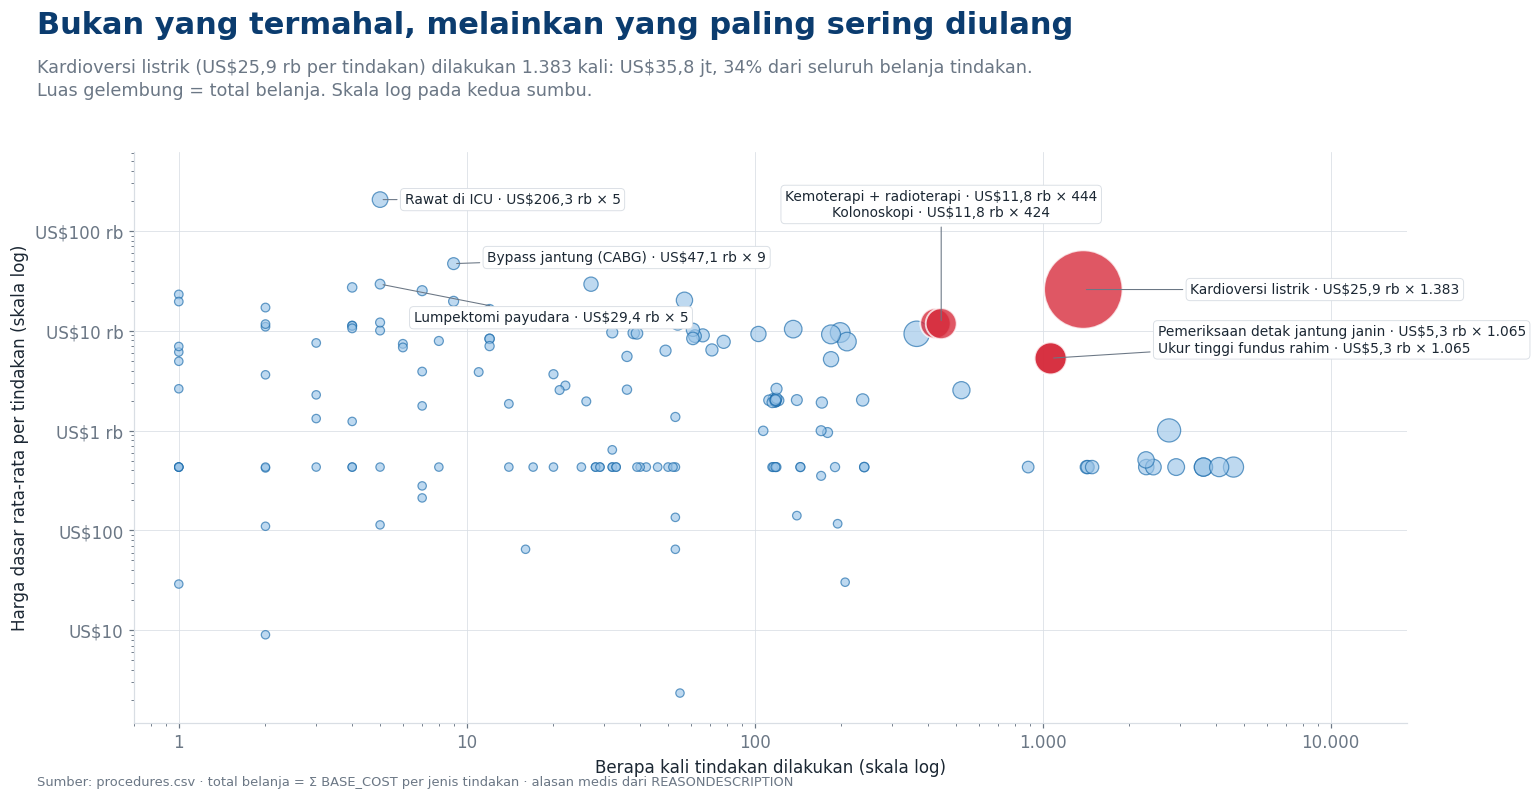

In [16]:
ps = proc_stats.copy()
top_spend = ps.nlargest(5, "total")
star = ps.total.idxmax()
star_row = ps.loc[star]
print(f"-> {star_row['name']}: {id_num(star_row.n)} kali × {usd(star_row.unit_cost)} = {usd(star_row.total)} "
      f"({pct(star_row.spend_share, 0)} dari seluruh belanja tindakan). Alasan utama: {star_row.reason}.")

fig, ax = plt.subplots(figsize=(13, 7.4))
top = add_header(fig, "Bukan yang termahal, melainkan yang paling sering diulang",
                 f"{star_row['name']} ({usd(star_row.unit_cost)} per tindakan) dilakukan {id_num(star_row.n)} kali: {usd(star_row.total)}, "
                 f"{pct(star_row.spend_share, 0)} dari seluruh belanja tindakan.\nLuas gelembung = total belanja. Skala log pada kedua sumbu.",
                 source="Sumber: procedures.csv · total belanja = Σ BASE_COST per jenis tindakan · alasan medis dari REASONDESCRIPTION")
fig.subplots_adjust(top=top - 0.02, bottom=0.1, left=0.08, right=0.97)
is_top = ps.index.isin(top_spend.index)
sizes = 30 + 2600 * (ps.total / ps.total.max())
ax.scatter(ps.n[~is_top], ps.unit_cost[~is_top], s=sizes[~is_top], color=BLUE_LIGHT, alpha=0.65, edgecolor=BLUE, linewidth=0.8, zorder=2)
ax.scatter(ps.n[is_top], ps.unit_cost[is_top], s=sizes[is_top], color=RED, alpha=0.78, edgecolor="white", linewidth=1.2, zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: id_num(v)))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: usd(v, 0)))
ax.set_xlabel("Berapa kali tindakan dilakukan (skala log)")
ax.set_ylabel("Harga dasar rata-rata per tindakan (skala log)")
ax.grid(color=GRAY_LIGHT, lw=0.5)
ax.set_axisbelow(True)
ax.set_ylim(ps.unit_cost.min() * 0.5, ps.unit_cost.max() * 3)
ax.set_xlim(0.7, ps.n.max() * 4)

label_idx = list(top_spend.index) + [i for i in ps[ps.n >= MIN_N].nlargest(3, "unit_cost").index if i not in top_spend.index]

# Gabungkan label untuk tindakan yang titiknya nyaris berimpit (selisih < 12% pada kedua sumbu) agar tidak saling menimpa
groups = []
for idx in label_idx:
    r = ps.loc[idx]
    for g in groups:
        if abs(np.log10(r.n / g["x"])) < 0.05 and abs(np.log10(r.unit_cost / g["y"])) < 0.05:
            g["items"].append(r)
            break
    else:
        groups.append({"x": r.n, "y": r.unit_cost, "items": [r]})

# (dx, dy, ha) dalam poin; kunci = nama tindakan pertama di grup
OFFSETS = {"Kardioversi listrik": (70, 0, "left"), "Rawat di ICU": (16, 0, "left"), "Bypass jantung (CABG)": (22, 4, "left"),
           "Lumpektomi payudara": (22, -22, "left"), "Kemoterapi + radioterapi": (0, 78, "center"),
           "Pemeriksaan detak jantung janin": (70, 12, "left")}
for g in groups:
    first = g["items"][0]["name"]
    dx, dy, ha = OFFSETS.get(first, (0, -62, "center"))
    text = "\n".join(f"{r['name']} · {usd(r.unit_cost)} × {id_num(r.n)}" for r in g["items"])
    ax.annotate(text, (g["x"], g["y"]), xytext=(dx, dy), textcoords="offset points", fontsize=9, color=INK, ha=ha, va="center",
                arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.7),
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRAY_LIGHT, lw=0.6), zorder=6)
save_fig(fig, "04b_harga_vs_frekuensi")
plt.show()

display(ps.nlargest(5, "total")[["name", "unit_cost", "n", "total", "spend_share", "reason"]].reset_index(drop=True).assign(
    unit_cost=lambda d: d.unit_cost.map(usd), total=lambda d: d.total.map(usd), spend_share=lambda d: d.spend_share.map(pct)).rename(
    columns={"name": "tindakan", "unit_cost": "harga rata-rata", "n": "jumlah", "total": "total belanja", "spend_share": "porsi", "reason": "alasan medis utama"}))

# BAGIAN 5 · Rapor pihak asuransi (The Resolution)
**Data:** `payers.csv` (`NAME`) di-join dengan `encounters.csv` (`PAYER_COVERAGE`) &nbsp;|&nbsp; **Visual:** dumbbell plot.

Setiap baris = satu penyedia. Titik merah = total biaya klaim, titik biru = bagian yang ditanggung, **garis di antaranya = "kesenjangan"**
yang harus ditutup pasien. Baris diurutkan dari rasio coverage tertinggi ke terendah.

Catatan: `NO_INSURANCE` ada di `payers.csv` sebagai satu "penyedia", padahal artinya tidak ada penyedia. Ia ditampilkan sebagai pembanding (garis dasar).

Rasio coverage tertinggi : Medicaid (94,0%)
Rasio coverage terendah  : Anthem (0,00%)
Beban pasien terbesar (nominal, di antara penyedia sungguhan): Medicare (US$5,4 jt) · karena volumenya (11.371 kunjungan), bukan karena rasionya
Kategori NO_INSURANCE    : US$49,3 jt beban pasien (70% dari seluruh beban)
[tersimpan] output_infografis/05_rapor_asuransi_dumbbell.png


,penyedia,kelompok,visits,patients,total,covered,oop,coverage_ratio
0,Medicaid,Asuransi aktif,1443,113,"US$9,0 jt","US$8,4 jt","US$536,2 rb","94,01%"
1,Dual Eligible,Asuransi aktif,912,62,"US$1,5 jt","US$1,4 jt","US$166,2 rb","89,25%"
2,Medicare,Asuransi aktif,11371,449,"US$24,6 jt","US$19,2 jt","US$5,4 jt","77,96%"
3,Blue Cross Blue Shield,Asuransi aktif,925,216,"US$3,0 jt","US$2,1 jt","US$927,7 rb","69,10%"
4,UnitedHealthcare,Asuransi cakupan ≈ 0%,900,206,"US$2,6 jt","US$3,9 rb","US$2,6 jt","0,15%"
5,Aetna,Asuransi cakupan ≈ 0%,936,207,"US$2,6 jt","US$1,8 rb","US$2,6 jt","0,07%"
6,Humana,Asuransi cakupan ≈ 0%,1084,219,"US$3,5 jt","US$2,0 rb","US$3,5 jt","0,06%"
7,Cigna Health,Asuransi cakupan ≈ 0%,809,203,"US$2,4 jt",US$968,"US$2,4 jt","0,04%"
8,Anthem,Asuransi cakupan ≈ 0%,704,204,"US$3,0 jt",US$0,"US$3,0 jt","0,00%"
9,NO_INSURANCE,Tanpa asuransi,8807,262,"US$49,3 jt",US$0,"US$49,3 jt","0,00%"


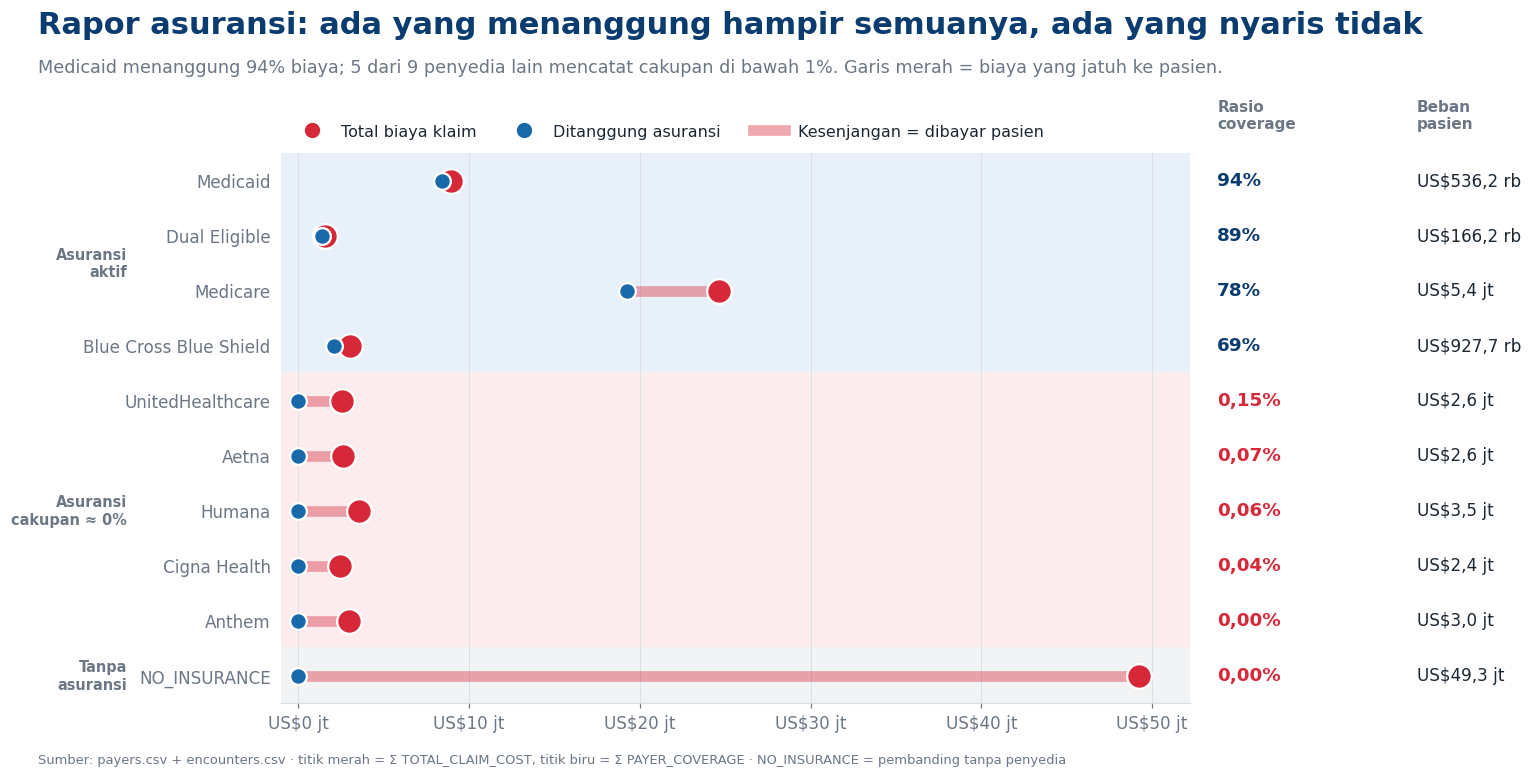

In [17]:
rk = payer_stats.sort_values(["coverage_ratio", "oop"], ascending=[False, True]).copy()
real = rk[rk.index != "NO_INSURANCE"]            # hanya penyedia sungguhan
best, worst = real.iloc[0], real.iloc[-1]
biggest_abs = real.oop.idxmax()

print(f"Rasio coverage tertinggi : {real.index[0]} ({pct(best.coverage_ratio)})")
print(f"Rasio coverage terendah  : {real.index[-1]} ({pct(worst.coverage_ratio, 2)})")
print(f"Beban pasien terbesar (nominal, di antara penyedia sungguhan): {biggest_abs} ({usd(real.oop.max())}) "
      f"· karena volumenya ({id_num(real.loc[biggest_abs, 'visits'])} kunjungan), bukan karena rasionya")
print(f"Kategori NO_INSURANCE    : {usd(payer_stats.loc['NO_INSURANCE', 'oop'])} beban pasien "
      f"({pct(payer_stats.loc['NO_INSURANCE', 'oop'] / payer_stats.oop.sum(), 0)} dari seluruh beban)")

n = len(rk)
y = np.arange(n)[::-1]
fig, ax = plt.subplots(figsize=(14, 7.2))
top = add_header(fig, "Rapor asuransi: ada yang menanggung hampir semuanya, ada yang nyaris tidak",
                 f"{real.index[0]} menanggung {pct(best.coverage_ratio, 0)} biaya; {sum(real.coverage_ratio < 0.01)} dari {len(real)} penyedia lain mencatat cakupan di bawah 1%. "
                 f"Garis merah = biaya yang jatuh ke pasien.",
                 source="Sumber: payers.csv + encounters.csv · titik merah = Σ TOTAL_CLAIM_COST, titik biru = Σ PAYER_COVERAGE · NO_INSURANCE = pembanding tanpa penyedia")
fig.subplots_adjust(top=top - 0.05, bottom=0.1, left=0.17, right=0.76)

# Pita latar per kelompok
band_color = {"Asuransi aktif": BLUE_PALE, "Asuransi cakupan ≈ 0%": RED_PALE, "Tanpa asuransi": "#F1F3F5"}
for grp_, sub in rk.groupby("group", sort=False):
    ys = [y[list(rk.index).index(i)] for i in sub.index]
    ax.axhspan(min(ys) - 0.5, max(ys) + 0.5, color=band_color[grp_], zorder=0)
    ax.text(-0.17, np.mean(ys), grp_.replace(" ", "\n", 1), transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=9.5, color=GRAY, fontweight="bold")

ax.hlines(y, rk.covered / 1e6, rk.total / 1e6, color=RED, lw=7, alpha=0.4, zorder=2)
ax.scatter(rk.total / 1e6, y, s=260, color=RED, zorder=4, edgecolor="white", linewidth=1.5)       # merah lebih besar agar tetap
ax.scatter(rk.covered / 1e6, y, s=120, color=BLUE, zorder=5, edgecolor="white", linewidth=1.5)    # terlihat bila kesenjangan kecil
ax.set_yticks(y, rk.index, fontsize=11)
ax.set_xlim(-1, rk.total.max() / 1e6 * 1.06)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"US${id_num(v, 0)} jt"))
ax.grid(axis="x", color=GRAY_LIGHT, lw=0.6)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(left=False)
ax.set_ylim(-0.5, n - 0.5)

# Kolom ringkasan di kanan
ax.text(1.03, n - 0.1, "Rasio\ncoverage", transform=ax.get_yaxis_transform(), fontsize=10, color=GRAY, fontweight="bold", va="bottom", ha="left")
ax.text(1.25, n - 0.1, "Beban\npasien", transform=ax.get_yaxis_transform(), fontsize=10, color=GRAY, fontweight="bold", va="bottom", ha="left")
for yy, (name, r) in zip(y, rk.iterrows()):
    ax.text(1.03, yy, pct(r.coverage_ratio, 2 if r.coverage_ratio < 0.01 else (1 if r.coverage_ratio < 0.1 else 0)), transform=ax.get_yaxis_transform(), fontsize=12, fontweight="bold",
            color=BLUE_DARK if r.coverage_ratio > 0.5 else RED, va="center", ha="left")
    ax.text(1.25, yy, usd(r.oop), transform=ax.get_yaxis_transform(), fontsize=11, color=INK, va="center", ha="left")

handles = [Line2D([], [], marker="o", color="w", markerfacecolor=RED, markersize=11, label="Total biaya klaim"),
           Line2D([], [], marker="o", color="w", markerfacecolor=BLUE, markersize=11, label="Ditanggung asuransi"),
           Line2D([], [], color=RED, lw=7, alpha=0.4, label="Kesenjangan = dibayar pasien")]
ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=10.5)
save_fig(fig, "05_rapor_asuransi_dumbbell")
plt.show()

display(rk.reset_index()[["PAYER_NAME", "group", "visits", "patients", "total", "covered", "oop", "coverage_ratio"]].assign(
    total=lambda d: d.total.map(usd), covered=lambda d: d.covered.map(usd), oop=lambda d: d.oop.map(usd),
    coverage_ratio=lambda d: d.coverage_ratio.map(lambda v: pct(v, 2))).rename(columns={"PAYER_NAME": "penyedia", "group": "kelompok"}))

# BAGIAN 6 · Bonus: pendalaman cerita
Tiga lapisan tambahan yang membuat infografis lebih dari sekadar deskriptif: **siapa yang memikul beban** (konsentrasi),
**kapan seseorang tidak terlindungi** (jurang usia), dan **apakah keadaan membaik** (tren).

### 6a. Konsentrasi beban: segelintir pasien memikul sebagian besar tagihan

1 pasien teratas = 14% dari seluruh beban pasien · 10 pasien (1%) = 43% · 98 pasien (10%) = 80% · 20% pasien = 89%
Median beban per pasien: US$8,6 rb · rata-rata: US$72,3 rb (rata-rata ditarik oleh segelintir pasien)
[tersimpan] output_infografis/06a_konsentrasi_beban.png


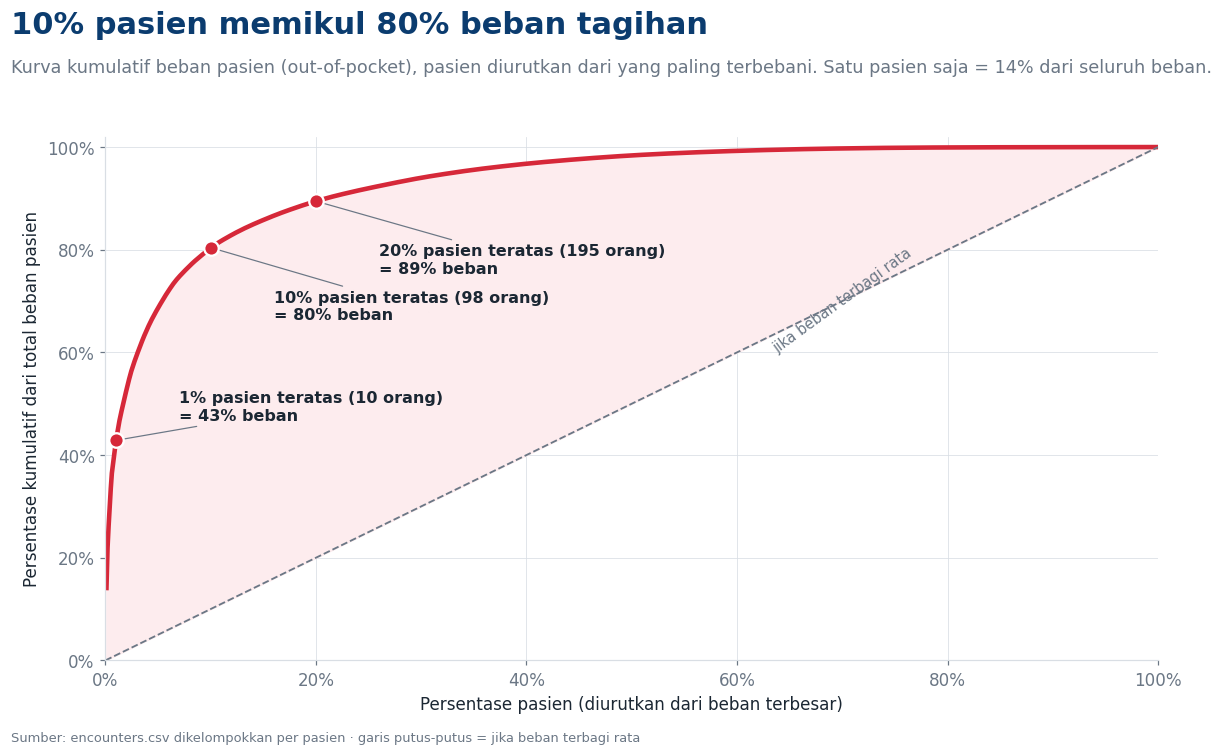

In [18]:
oop_sorted = pt.oop.sort_values(ascending=False).to_numpy()
cum = np.cumsum(oop_sorted) / oop_sorted.sum()
xp = np.arange(1, len(cum) + 1) / len(cum)


def share_of_top(frac):
    k = max(1, int(np.ceil(frac * len(cum))))
    return cum[k - 1], k


s1, k1 = share_of_top(0.01)
s10, k10 = share_of_top(0.10)
s20, _ = share_of_top(0.20)
top1_share = oop_sorted[0] / oop_sorted.sum()
print(f"1 pasien teratas = {pct(top1_share, 0)} dari seluruh beban pasien · {k1} pasien (1%) = {pct(s1, 0)} · {k10} pasien (10%) = {pct(s10, 0)} · 20% pasien = {pct(s20, 0)}")
print(f"Median beban per pasien: {usd(pt.oop.median())} · rata-rata: {usd(pt.oop.mean())} (rata-rata ditarik oleh segelintir pasien)")

fig, ax = plt.subplots(figsize=(11, 7))
top = add_header(fig, f"{pct(0.10, 0)} pasien memikul {pct(s10, 0)} beban tagihan",
                 f"Kurva kumulatif beban pasien (out-of-pocket), pasien diurutkan dari yang paling terbebani. Satu pasien saja = {pct(top1_share, 0)} dari seluruh beban.",
                 source="Sumber: encounters.csv dikelompokkan per pasien · garis putus-putus = jika beban terbagi rata")
fig.subplots_adjust(top=top - 0.03, bottom=0.13, left=0.09, right=0.96)
ax.fill_between(xp * 100, cum * 100, xp * 100, color=RED_PALE)
ax.plot(xp * 100, cum * 100, color=RED, lw=3)
ax.plot([0, 100], [0, 100], color=GRAY, lw=1.2, ls="--")
for frac, share, k, dy in [(0.01, s1, k1, 4), (0.10, s10, k10, -14), (0.20, s20, int(np.ceil(0.2 * len(cum))), -14)]:
    ax.scatter([frac * 100], [share * 100], s=90, color=RED, zorder=5, edgecolor="white", linewidth=1.5)
    ax.annotate(f"{pct(frac, 0)} pasien teratas ({k} orang)\n= {pct(share, 0)} beban", (frac * 100, share * 100), xytext=(frac * 100 + 6, share * 100 + dy),
                fontsize=10.5, fontweight="bold", color=INK, arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))
ax.text(70, 60, "jika beban terbagi rata", rotation=36, fontsize=9.5, color=GRAY, ha="center")
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Persentase pasien (diurutkan dari beban terbesar)")
ax.set_ylabel("Persentase kumulatif dari total beban pasien")
ax.grid(color=GRAY_LIGHT, lw=0.5)
ax.set_axisbelow(True)
save_fig(fig, "06a_konsentrasi_beban")
plt.show()

### 6b. Jurang usia: kapan seseorang paling tidak terlindungi?

Kelompok usia dengan coverage terendah: 50–64 (14%) · usia termuda pada kunjungan Medicare: 65,0 tahun


PAYER_GROUP,Asuransi aktif,Asuransi cakupan ≈ 0%,Tanpa asuransi
AGE_GROUP,,,
<35,30%,34%,36%
35–49,29%,51%,20%
50–64,20%,55%,25%
65+,65%,0%,34%


[tersimpan] output_infografis/06b_jurang_usia.png


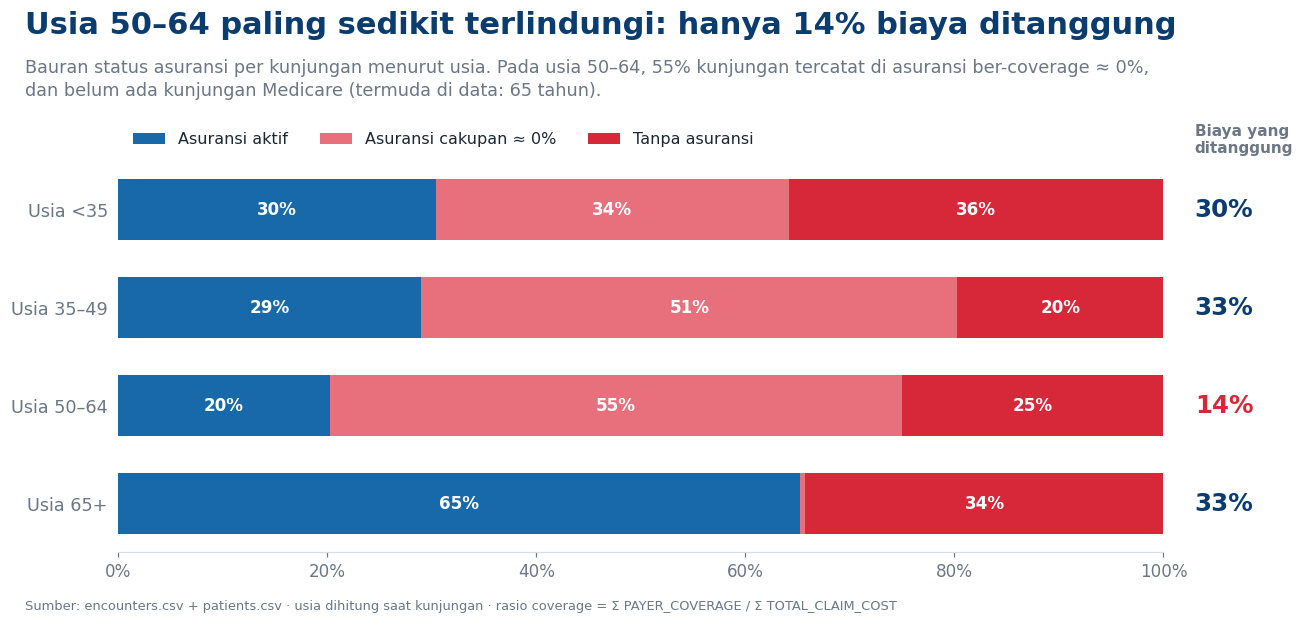

In [19]:
am = pd.crosstab(enc.AGE_GROUP, enc.PAYER_GROUP, normalize="index").reindex(columns=GROUP_ORDER, fill_value=0)
am = am.loc[AGE_LABELS]
cov_by_age = age_tbl.coverage_ratio.reindex(AGE_LABELS)
low_age = cov_by_age.idxmin()
medicare_min_age = enc.loc[enc.PAYER_NAME == "Medicare", "AGE"].min()
print(f"Kelompok usia dengan coverage terendah: {low_age} ({pct(cov_by_age.min(), 0)}) · usia termuda pada kunjungan Medicare: {id_num(medicare_min_age, 1)} tahun")
display(am.map(lambda v: pct(v, 0)) if hasattr(am, "map") else am.applymap(lambda v: pct(v, 0)))

fig, ax = plt.subplots(figsize=(12.5, 5.8))
zero_share_low = am.loc[low_age, "Asuransi cakupan ≈ 0%"]
top = add_header(fig, f"Usia {low_age} paling sedikit terlindungi: hanya {pct(cov_by_age.min(), 0)} biaya ditanggung",
                 f"Bauran status asuransi per kunjungan menurut usia. Pada usia {low_age}, {pct(zero_share_low, 0)} kunjungan tercatat di asuransi ber-coverage ≈ 0%,\n"
                 f"dan belum ada kunjungan Medicare (termuda di data: {id_num(medicare_min_age, 0)} tahun).",
                 source="Sumber: encounters.csv + patients.csv · usia dihitung saat kunjungan · rasio coverage = Σ PAYER_COVERAGE / Σ TOTAL_CLAIM_COST")
fig.subplots_adjust(top=top - 0.04, bottom=0.12, left=0.08, right=0.84)
colors_ = {"Asuransi aktif": BLUE, "Asuransi cakupan ≈ 0%": RED_MID, "Tanpa asuransi": RED}
yy = np.arange(len(AGE_LABELS))[::-1]
left = np.zeros(len(AGE_LABELS))
for g in GROUP_ORDER:
    vals = am[g].to_numpy() * 100
    ax.barh(yy, vals, left=left, color=colors_[g], height=0.62, label=g)
    for yv, v, l in zip(yy, vals, left):
        if v >= 6:
            ax.text(l + v / 2, yv, f"{v:.0f}%".replace(".", ","), ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    left += vals
ax.set_yticks(yy, [f"Usia {a}" for a in AGE_LABELS], fontsize=11.5)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.spines["left"].set_visible(False)
ax.tick_params(left=False)
ax.text(1.03, len(AGE_LABELS) - 0.45, "Biaya yang\nditanggung", transform=ax.get_yaxis_transform(), fontsize=10, color=GRAY, fontweight="bold", va="bottom")
for yv, a in zip(yy, AGE_LABELS):
    c = cov_by_age[a]
    ax.text(1.03, yv, pct(c, 0), transform=ax.get_yaxis_transform(), fontsize=16, fontweight="bold", color=RED if a == low_age else BLUE_DARK, va="center")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=10.5)
save_fig(fig, "06b_jurang_usia")
plt.show()

### 6c. Apakah keadaan membaik dari tahun ke tahun?

      visits       total    covered coverage_ratio
YEAR                                              
2011    1336   US$4,4 jt  US$2,1 jt          47,4%
2012    2106   US$9,1 jt  US$2,9 jt          31,7%
2013    2495  US$10,1 jt  US$3,4 jt          33,9%
2014    3885  US$12,0 jt  US$3,6 jt          29,6%
2015    2469  US$10,1 jt  US$3,0 jt          29,4%
2016    2451   US$8,4 jt  US$2,2 jt          25,7%
2017    2360   US$9,6 jt  US$3,0 jt          31,2%
2018    2292   US$8,7 jt  US$2,0 jt          23,0%
2019    2228   US$8,9 jt  US$2,9 jt          32,1%
2020    2519  US$10,3 jt  US$3,0 jt          29,5%
2021    3530   US$9,2 jt  US$2,9 jt          31,2%
[tersimpan] output_infografis/06c_tren_tahunan.png


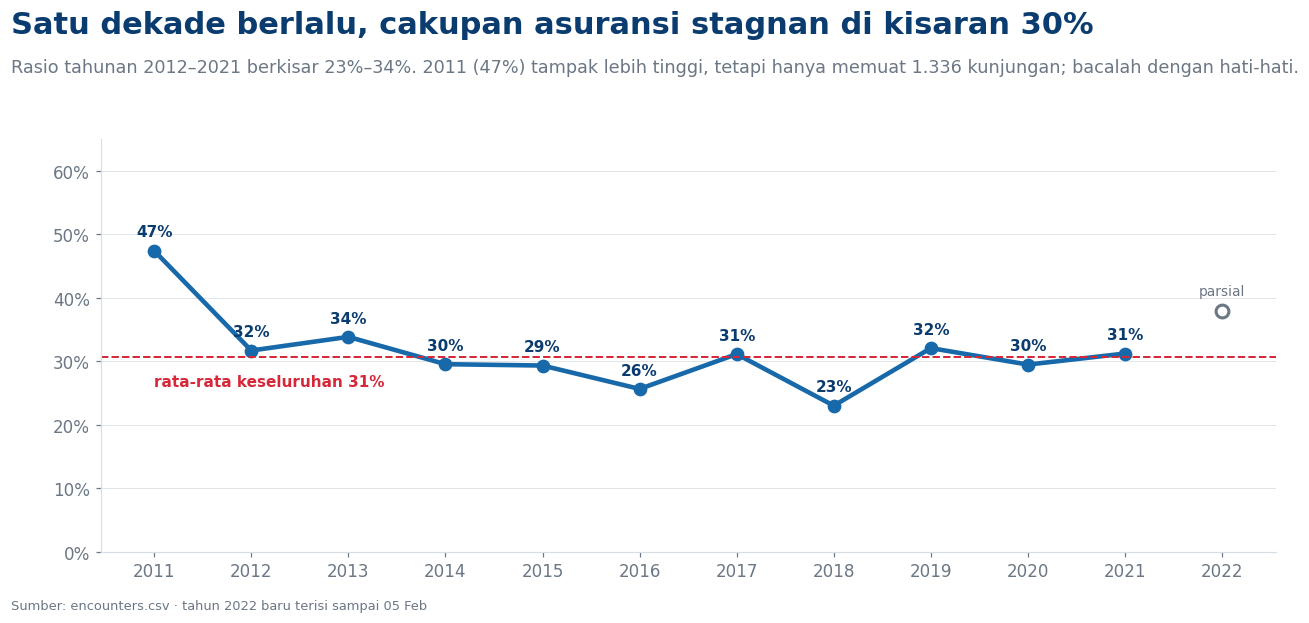

In [20]:
yr = enc.groupby("YEAR").agg(visits=("Id", "count"), total=("TOTAL_CLAIM_COST", "sum"), covered=("PAYER_COVERAGE", "sum"))
yr["coverage_ratio"] = yr.covered / yr.total
last_year = yr.index.max()
partial = enc.START.max() < pd.Timestamp(f"{last_year}-12-01")      # tahun terakhir belum lengkap
full = yr.iloc[:-1] if partial else yr
print(full.assign(total=lambda d: d.total.map(usd), covered=lambda d: d.covered.map(usd), coverage_ratio=lambda d: d.coverage_ratio.map(pct)).to_string())

fig, ax = plt.subplots(figsize=(12, 5.8))
core = full.iloc[1:]                       # tahun pertama (volume kecil) dipisahkan dari pembacaan tren
top = add_header(fig, f"Satu dekade berlalu, cakupan asuransi stagnan di kisaran {pct(core.coverage_ratio.median(), 0)}",
                 f"Rasio tahunan {core.index[0]}–{core.index[-1]} berkisar {pct(core.coverage_ratio.min(), 0)}–{pct(core.coverage_ratio.max(), 0)}. "
                 f"{full.index[0]} ({pct(full.coverage_ratio.iloc[0], 0)}) tampak lebih tinggi, tetapi hanya memuat {id_num(full.visits.iloc[0])} kunjungan; bacalah dengan hati-hati.",
                 source=f"Sumber: encounters.csv · tahun {last_year} baru terisi sampai {enc.START.max():%d %b}" if partial else "Sumber: encounters.csv")
fig.subplots_adjust(top=top - 0.04, bottom=0.12, left=0.08, right=0.97)
ax.plot(full.index, full.coverage_ratio * 100, color=BLUE, lw=3, marker="o", ms=8)
for x_, v in zip(full.index, full.coverage_ratio * 100):
    ax.text(x_, v + 2.2, f"{v:.0f}%", ha="center", fontsize=10, color=BLUE_DARK, fontweight="bold")
if partial:
    ax.scatter([last_year], [yr.coverage_ratio.iloc[-1] * 100], s=70, facecolor="white", edgecolor=GRAY, linewidth=2, zorder=5)
    ax.text(last_year, yr.coverage_ratio.iloc[-1] * 100 + 2.5, "parsial", ha="center", fontsize=9, color=GRAY)
ax.axhline(cov_ratio * 100, color=RED, lw=1.3, ls="--")
ax.text(full.index.min(), cov_ratio * 100 - 4.5, f"rata-rata keseluruhan {pct(cov_ratio, 0)}", color=RED, fontsize=10, fontweight="bold")
ax.set_ylim(0, 65)
ax.set_xticks(yr.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", color=GRAY_LIGHT, lw=0.5)
ax.set_axisbelow(True)
save_fig(fig, "06c_tren_tahunan")
plt.show()

# PENUTUP · Call-to-Action
*"Memahami polis asuransi dan prosedur medis Anda adalah langkah pertama menuju kesehatan finansial dan fisik."*
Tiga tindakan konkret, masing-masing ditambatkan pada satu angka dari data.

[tersimpan] output_infografis/07_call_to_action.png


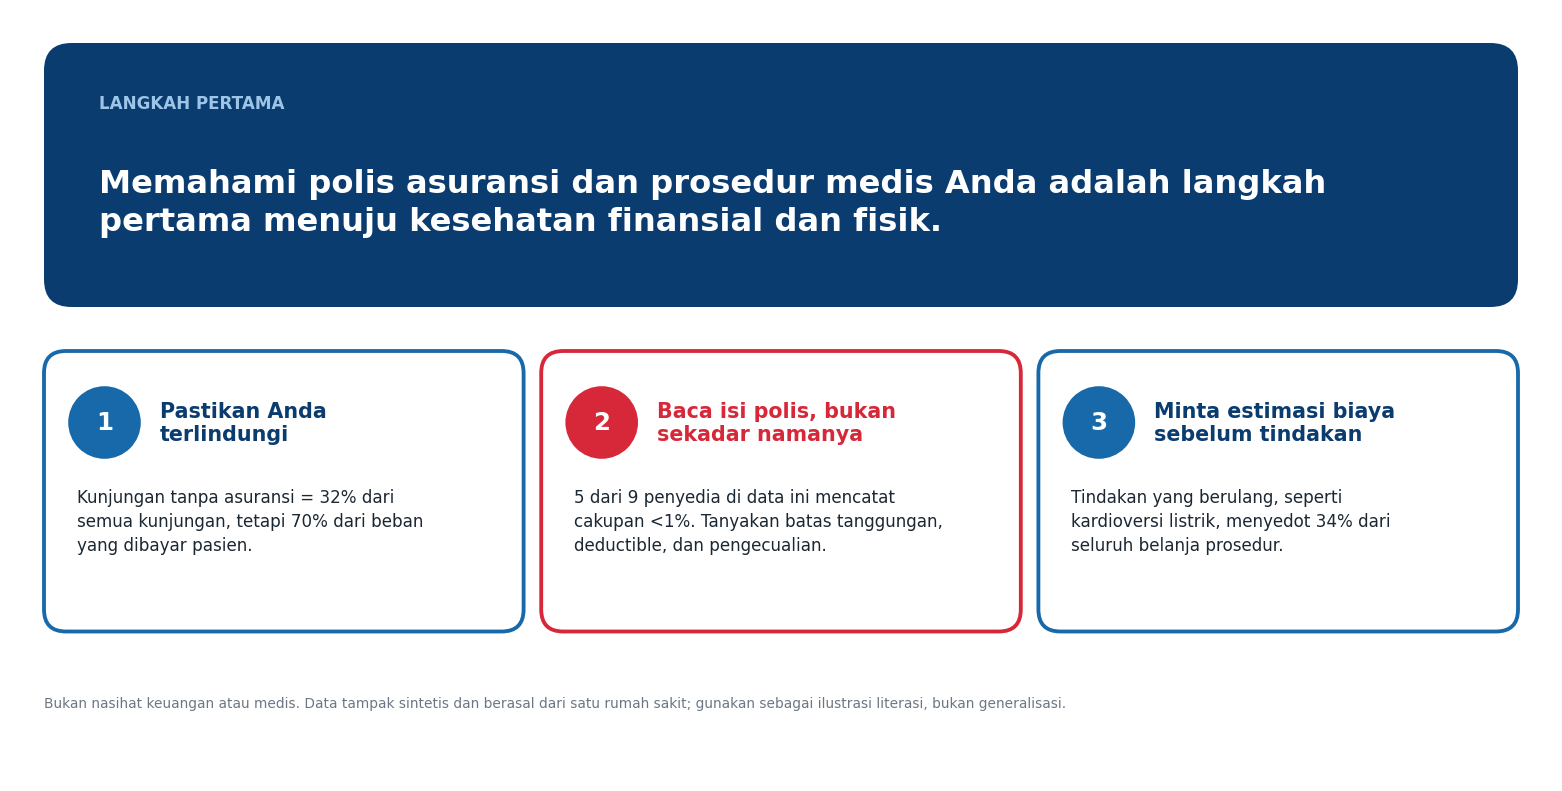

In [21]:
ni = payer_stats.loc["NO_INSURANCE"]
ni_visit_share = ni.visits / payer_stats.visits.sum()
ni_cost_share = ni.total / payer_stats.total.sum()
ni_oop_share = ni.oop / payer_stats.oop.sum()
n_zero = int((real.coverage_ratio < 0.01).sum())

fig = plt.figure(figsize=(14, 7))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 14)
ax.set_ylim(0, 7)
ax.axis("off")
ax.add_patch(FancyBboxPatch((0.3, 4.3), 13.4, 2.4, boxstyle="round,pad=0,rounding_size=0.25", facecolor=BLUE_DARK, edgecolor="none"))
ax.text(0.8, 6.15, "LANGKAH PERTAMA", fontsize=11, color=BLUE_LIGHT, fontweight="bold", va="center")
ax.text(0.8, 5.25, textwrap.fill("Memahami polis asuransi dan prosedur medis Anda adalah langkah pertama menuju kesehatan finansial dan fisik.", 62),
        fontsize=21, color="white", fontweight="bold", va="center", linespacing=1.3)
cards = [
    ("1", "Pastikan Anda terlindungi", f"Kunjungan tanpa asuransi = {pct(ni_visit_share, 0)} dari semua kunjungan, "
                                        f"tetapi {pct(ni_oop_share, 0)} dari beban yang dibayar pasien.", BLUE),
    ("2", "Baca isi polis, bukan sekadar namanya", f"{n_zero} dari {len(real)} penyedia di data ini mencatat cakupan <1%. "
                                                  f"Tanyakan batas tanggungan, deductible, dan pengecualian.", RED),
    ("3", "Minta estimasi biaya sebelum tindakan", f"Tindakan yang berulang, seperti {star_row['name'].lower()}, "
                                                    f"menyedot {pct(star_row.spend_share, 0)} dari seluruh belanja prosedur.", BLUE),
]
for i, (num, head, body, col) in enumerate(cards):
    x0 = 0.3 + i * 4.52
    ax.add_patch(FancyBboxPatch((x0, 1.35), 4.36, 2.55, boxstyle="round,pad=0,rounding_size=0.2", facecolor="white", edgecolor=col, linewidth=2.5))
    ax.add_patch(Circle((x0 + 0.55, 3.25), 0.33, facecolor=col, edgecolor="none"))
    ax.text(x0 + 0.55, 3.25, num, color="white", fontsize=16, fontweight="bold", ha="center", va="center")
    ax.text(x0 + 1.05, 3.25, textwrap.fill(head, 24), fontsize=13.5, fontweight="bold", color=col if col == RED else BLUE_DARK, va="center", linespacing=1.2)
    ax.text(x0 + 0.3, 2.65, textwrap.fill(body, 40), fontsize=11, color=INK, va="top", linespacing=1.4)
ax.text(0.3, 0.7, "Bukan nasihat keuangan atau medis. Data tampak sintetis dan berasal dari satu rumah sakit; gunakan sebagai ilustrasi literasi, bukan generalisasi.",
        fontsize=9, color=GRAY, va="center")
save_fig(fig, "07_call_to_action")
plt.show()

## Draft narasi siap pakai
Kalimat di bawah dihitung langsung dari data, sehingga angkanya selalu konsisten dengan grafik. Salin ke desain infografis.

In [22]:
age_rows = demo_burden[(demo_burden.dimension == "Usia terakhir tercatat") & (demo_burden.n >= 30)].copy()
age_rows["group"] = age_rows.group.astype(str)
hi_age, lo_age = age_rows.loc[age_rows.med_oop.idxmax()], age_rows.loc[age_rows.med_oop.idxmin()]
t1 = top5.iloc[0]

copy_lines = {
    "1 · Hook": [
        f"Dari {usd(total)} klaim biaya kesehatan, hanya {pct(cov_ratio, 0)} ditanggung asuransi. Sisanya, {usd(oop)} ({pct(1 - cov_ratio, 0)}), dibayar pasien.",
        f"Angka itu menyembunyikan dua dunia: asuransi aktif menanggung {pct(g_act.coverage_ratio, 0)}, sedangkan {pct(g_none.oop_share + g_zero.oop_share, 0)} beban pasien datang dari kunjungan tanpa asuransi atau asuransi ber-coverage ≈ 0%.",
    ],
    "2 · Pasien": [
        f"Usia {top_age} = {pct(age_tbl.visit_share.max(), 0)} dari seluruh kunjungan ({age_tbl.loc[top_age, 'visits_per_patient']:.0f} kunjungan per pasien).",
        f"Tetapi yang paling terbebani per orang adalah usia {hi_age.group} (median {usd(hi_age.med_oop)}), sedangkan usia {lo_age.group} hanya {usd(lo_age.med_oop)}.",
        f"{pct(s10, 0)} beban pasien dipikul oleh 10% pasien; satu pasien saja = {pct(top1_share, 0)}.",
    ],
    "3 · Kunjungan": [
        f"Semua {id_num(n_visits)} kunjungan terjadi di {fac_txt.lower()}, dari pasien di {len(city_tbl)} kota ({pct(city_tbl.patients.iloc[0] / city_tbl.patients.sum(), 0)} dari {city_tbl.index[0]}).",
        f"{gap_row.label}: {pct(gap_row.visit_share, 0)} kunjungan, tetapi {pct(gap_row.cost_share, 0)} biaya. {priciest.label} termahal per kunjungan ({usd(priciest.mean_claim)}); coverage terendah ada di {leakiest.label} ({pct(leakiest.coverage_ratio, 0)}).",
    ],
    "4 · Prosedur": [
        f"Termahal per tindakan: {t1['name']} ({usd(t1.unit_cost)}), alasan: {t1.reason}.",
        f"Paling menguras dana: {star_row['name']}, {id_num(star_row.n)} kali × {usd(star_row.unit_cost)} = {usd(star_row.total)} ({pct(star_row.spend_share, 0)} belanja tindakan), alasan: {star_row.reason}.",
    ],
    "5 · Asuransi": [
        f"Rasio coverage tertinggi: {real.index[0]} ({pct(best.coverage_ratio, 0)}). Terendah: {real.index[-1]} ({pct(worst.coverage_ratio, 2)}).",
        f"Secara nominal, beban terbesar di antara penyedia sungguhan ada pada {biggest_abs} ({usd(real.oop.max())}), karena volume kunjungannya. Kategori tanpa asuransi: {usd(ni.oop)}.",
    ],
    "6 · Bonus": [
        f"Usia {low_age}: hanya {pct(cov_by_age.min(), 0)} biaya yang ditanggung ({pct(zero_share_low, 0)} kunjungan ada di asuransi ber-coverage ≈ 0%; kunjungan Medicare termuda berusia {id_num(medicare_min_age, 0)} tahun).",
        f"Cakupan stagnan di kisaran {pct(core.coverage_ratio.median(), 0)} sepanjang {core.index[0]}–{core.index[-1]}.",
    ],
}
for section, lines in copy_lines.items():
    print(f"[{section}]")
    for l in lines:
        print("  -", l)

[1 · Hook]
  - Dari US$101,5 jt klaim biaya kesehatan, hanya 31% ditanggung asuransi. Sisanya, US$70,4 jt (69%), dibayar pasien.
  - Angka itu menyembunyikan dua dunia: asuransi aktif menanggung 81%, sedangkan 90% beban pasien datang dari kunjungan tanpa asuransi atau asuransi ber-coverage ≈ 0%.
[2 · Pasien]
  - Usia 65+ = 68% dari seluruh kunjungan (34 kunjungan per pasien).
  - Tetapi yang paling terbebani per orang adalah usia 50–64 (median US$20,7 rb), sedangkan usia 65+ hanya US$6,3 rb.
  - 80% beban pasien dipikul oleh 10% pasien; satu pasien saja = 14%.
[3 · Kunjungan]
  - Semua 27.891 kunjungan terjadi di satu rumah sakit, dari pasien di 29 kota (56% dari Boston).
  - Urgent care: 13% kunjungan, tetapi 23% biaya. Inpatient (rawat inap) termahal per kunjungan (US$7,8 rb); coverage terendah ada di Urgent care (13%).
[4 · Prosedur]
  - Termahal per tindakan: Rawat di ICU (US$206,3 rb), alasan: Septic shock (syok septik).
  - Paling menguras dana: Kardioversi listrik, 1.383 kali × 

## Ekspor: angka kunci & tabel pendukung untuk tim desain

In [23]:
key_numbers = {
    "periode": years, "kunjungan": int(n_visits), "pasien": int(n_patients), "total_klaim_usd": round(float(total), 2),
    "ditanggung_asuransi_usd": round(float(covered), 2), "dibayar_pasien_usd": round(float(oop), 2),
    "rasio_coverage_agregat": round(float(cov_ratio), 4), "rasio_coverage_rata2_per_kunjungan": round(float(mean_ratio_per_visit), 4),
    "rasio_coverage_asuransi_aktif": round(float(g_act.coverage_ratio), 4),
    "porsi_beban_dari_tanpa_asuransi_dan_cakupan_0": round(float(g_none.oop_share + g_zero.oop_share), 4),
    "porsi_kunjungan_usia_tertinggi": {"kelompok": str(top_age), "porsi": round(float(age_tbl.visit_share.max()), 4)},
    "pasien_10persen_teratas_porsi_beban": round(float(s10), 4), "pasien_teratas_porsi_beban": round(float(top1_share), 4),
    "penyedia_coverage_tertinggi": {"nama": real.index[0], "rasio": round(float(best.coverage_ratio), 4)},
    "penyedia_coverage_terendah": {"nama": real.index[-1], "rasio": round(float(worst.coverage_ratio), 6)},
    "prosedur_termahal_satuan": {"nama": t1["name"], "harga": round(float(t1.unit_cost), 0), "kasus": int(t1.n)},
    "prosedur_total_belanja_terbesar": {"nama": star_row["name"], "total": round(float(star_row.total), 0), "porsi": round(float(star_row.spend_share), 4)},
    "usia_coverage_terendah": {"kelompok": str(low_age), "rasio_coverage": round(float(cov_by_age.min()), 4)},
    "tren_tahunan_median_rasio": round(float(core.coverage_ratio.median()), 4),
}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key_numbers, ensure_ascii=False, indent=2), encoding="utf-8")
payer_stats.to_csv(OUT_DIR / "tabel_payer.csv")
class_stats.drop(columns="label").to_csv(OUT_DIR / "tabel_jenis_kunjungan.csv")
proc_stats.sort_values("total", ascending=False).to_csv(OUT_DIR / "tabel_prosedur.csv")
demo_burden.drop(columns="y").to_csv(OUT_DIR / "tabel_demografi.csv", index=False)
city_tbl.to_csv(OUT_DIR / "tabel_kota_asal_pasien.csv")

print("File di folder output_infografis/:")
for f in sorted(OUT_DIR.glob("*")):
    print(f"  {f.name:40s} {f.stat().st_size / 1024:8.0f} KB")

File di folder output_infografis/:
  01a_hook_donat.png                            219 KB
  01b_bongkar_beban.png                         170 KB
  02a_isotype_pasien.png                        480 KB
  02b_beban_per_demografi.png                   275 KB
  03a_volume_vs_biaya.png                       196 KB
  03b_biaya_per_kunjungan.png                   222 KB
  03c_peta_asal_pasien.png                      413 KB
  04a_top5_prosedur_termahal.png                321 KB
  04b_harga_vs_frekuensi.png                    356 KB
  05_rapor_asuransi_dumbbell.png                299 KB
  06a_konsentrasi_beban.png                     253 KB
  06b_jurang_usia.png                           194 KB
  06c_tren_tahunan.png                          167 KB
  07_call_to_action.png                         220 KB
  key_numbers.json                                1 KB
  tabel_demografi.csv                             1 KB
  tabel_jenis_kunjungan.csv                       1 KB
  tabel_kota_asal_pasien.csv  

## Catatan, batasan & langkah berikutnya

**Batasan data**
1. **Data sintetis, satu rumah sakit.** Pola seperti "lima asuransi dengan cakupan ≈ 0%" kemungkinan merupakan artefak simulasi dan tidak boleh digeneralisasi ke perusahaan asuransi sungguhan. Sampaikan ini di infografis.
2. **Beban pasien = klaim − cakupan** adalah aproksimasi; data tidak mencatat bantuan pihak ketiga atau tunggakan.
3. **Rata-rata sangat ditarik oleh nilai ekstrem** (satu pasien ≈ 14% seluruh beban). Karena itu perbandingan kelompok memakai median, dan kelompok dengan n < 30 ditandai.
4. **Perbedaan antar-ras/gender tidak dapat ditafsirkan sebagai sebab-akibat**: tidak dikontrol terhadap usia, penyakit, atau status asuransi.
5. Tahun terakhir data belum lengkap; tahun awal memuat jumlah kunjungan yang jauh lebih sedikit.
6. `REASONDESCRIPTION` pada prosedur hanya terisi untuk sebagian kecil baris, sehingga "alasan medis" adalah alasan yang *tercatat*, bukan seluruh alasan.

**Langkah berikutnya untuk infografis:** rakit PNG di `output_infografis/` dalam Figma/Canva/Illustrator mengikuti urutan 01 → 07,
gunakan `key_numbers.json` untuk teks, dan ganti panel isotype/donat dengan ilustrasi bila ingin gaya yang lebih editorial
(lihat dokumen storyboard untuk rekomendasi visual per bagian).